# EcoMove sustainable mobility investigation (COM7021)

**Student ID: 25138486**

All analysis for the report, from the raw file to the final figures, in one notebook.

- **Part 1 - Analysis walkthrough.** Loads the dataset, checks and prepares it, and runs the statistics quoted in the report. Each "Screenshot" heading matches the screenshot with the same number in the report. Screenshot 19 is the dashboard test run (`test_dashboard.py`), so it is not in this notebook.
- **Part 2 - Visualisations.** Builds the exploratory charts and the main report figures, with the supporting statistics (bootstrap confidence intervals, regression tables). Figures are saved to a `figures` folder.

**To run:** keep `[5442] EcoMoveMobility.xlsx` (or `EcoMoveMobility.xlsx`) in the same folder as this notebook, install the packages (`pip install pandas numpy scipy statsmodels scikit-posthocs matplotlib openpyxl`) and choose _Restart and Run All_.

The script `ecomove_analysis.py` contains exactly the same code in the same order.

# Part 1 - Analysis walkthrough

## Screenshot 1 - Import libraries and load the dataset

In [1]:
import sys
from pathlib import Path

import matplotlib
if 'ipykernel' not in sys.modules:   # plain script: save figures to files instead of opening windows
    matplotlib.use('Agg')
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.formula.api as smf
import scikit_posthocs as sp

try:                     # display() exists in notebooks; in a plain script, print instead
    display
except NameError:
    display = print

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

# the brief names the file '[5442] EcoMoveMobility.xlsx'; a copy without the prefix also works
DATA_FILE = next(p for p in ['[5442] EcoMoveMobility.xlsx', 'EcoMoveMobility.xlsx'] if Path(p).exists())
raw = pd.read_excel(DATA_FILE)
print('File:', DATA_FILE)
print('Shape (rows, columns):', raw.shape)
print('Cities:', raw['City'].nunique(), '| Countries:', raw['Country'].nunique())
dates = pd.to_datetime(raw['Date'], unit='D', origin='1899-12-30')  # Excel stores dates as serial numbers
print('Date range:', dates.min().date(), 'to', dates.max().date())

File: EcoMoveMobility.xlsx
Shape (rows, columns): (5000, 18)
Cities: 12 | Countries: 6
Date range: 2024-01-01 to 2025-12-31


## Screenshot 2 - Column names and data types as loaded

In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Record_ID                 5000 non-null   str    
 1   Date                      5000 non-null   int64  
 2   City                      5000 non-null   str    
 3   Country                   5000 non-null   str    
 4   Transport_Mode            5000 non-null   str    
 5   Route_Type                5000 non-null   str    
 6   Weather                   5000 non-null   str    
 7   Event_Day                 5000 non-null   str    
 8   Passengers                5000 non-null   int64  
 9   Trips                     5000 non-null   int64  
 10  Average_Delay_Minutes     5000 non-null   float64
 11  On_Time_Percentage        5000 non-null   float64
 12  Ticket_Revenue_EUR        5000 non-null   float64
 13  Operating_Cost_EUR        5000 non-null   float64
 14  CO2_Saved_KG       

## Screenshot 3 - Missing, duplicate and out-of-range checks

In [3]:
print('Missing values:', raw.isna().sum().sum())
print('Duplicate rows:', raw.duplicated().sum())
print('Duplicate Record_IDs:', raw['Record_ID'].duplicated().sum())
print('Negative values:', (raw.select_dtypes('number') < 0).sum().sum())
print('On-time % outside 0-100:', (~raw['On_Time_Percentage'].between(0, 100)).sum())
print('Ratings outside 1-5:', (~raw['Customer_Rating'].between(1, 5)).sum())

Missing values: 0
Duplicate rows: 0
Duplicate Record_IDs: 0
Negative values: 0
On-time % outside 0-100: 0
Ratings outside 1-5: 0


## Screenshot 4 - Convert dates and text columns

In [4]:
df = raw.copy()
df['Date'] = dates                                    # converted in Screenshot 1
for col in ['City', 'Country', 'Transport_Mode', 'Route_Type', 'Weather', 'Event_Day']:
    df[col] = df[col].astype('category')

print('Rows kept:', len(df), 'of', len(raw))
print('Passengers kept:', df['Passengers'].sum(), 'of', raw['Passengers'].sum())
df.info()

Rows kept: 5000 of 5000
Passengers kept: 40909721 of 40909721
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype        
---  ------                    --------------  -----        
 0   Record_ID                 5000 non-null   str          
 1   Date                      5000 non-null   datetime64[s]
 2   City                      5000 non-null   category     
 3   Country                   5000 non-null   category     
 4   Transport_Mode            5000 non-null   category     
 5   Route_Type                5000 non-null   category     
 6   Weather                   5000 non-null   category     
 7   Event_Day                 5000 non-null   category     
 8   Passengers                5000 non-null   int64        
 9   Trips                     5000 non-null   int64        
 10  Average_Delay_Minutes     5000 non-null   float64      
 11  On_Time_Percentage        5000 non-null   fl

## Screenshot 5 - Add derived measures

In [5]:
df['Operating_Surplus_EUR'] = df['Ticket_Revenue_EUR'] - df['Operating_Cost_EUR']
df['Revenue_Cost_Ratio'] = df['Ticket_Revenue_EUR'] / df['Operating_Cost_EUR']
df['Complaints_per_10k'] = df['Accessibility_Complaints'] / df['Passengers'] * 10_000
df['CO2_per_Passenger'] = df['CO2_Saved_KG'] / df['Passengers']
df['Cost_per_Passenger'] = df['Operating_Cost_EUR'] / df['Passengers']
df['Year'], df['Month'] = df['Date'].dt.year, df['Date'].dt.month
df['Weekday'] = df['Date'].dt.day_name().str[:3]
df['Micromobility'] = df['Transport_Mode'].isin(['Bike Share', 'E-Scooter'])

display(df[['Transport_Mode', 'Operating_Surplus_EUR', 'Revenue_Cost_Ratio', 'Complaints_per_10k',
            'CO2_per_Passenger', 'Cost_per_Passenger']].head().round(2))

,Transport_Mode,Operating_Surplus_EUR,Revenue_Cost_Ratio,Complaints_per_10k,CO2_per_Passenger,Cost_per_Passenger
0,Tram,11049.61,1.23,11.33,0.09,2.08
1,Tram,3870.84,1.19,7.43,0.09,2.20
2,Tram,1039.27,1.07,10.82,0.11,2.18
3,Tram,2226.68,1.19,13.42,0.12,2.29
4,Metro,-1311.90,0.95,11.70,0.14,2.81


## Screenshot 6 - The six transport modes

In [6]:
modes = df.groupby('Transport_Mode', observed=True).agg(Records=('Passengers', 'size'),
                                                        Total_passengers=('Passengers', 'sum'),
                                                        Mean_per_record=('Passengers', 'mean'))
modes['% of records'] = 100 * modes['Records'] / len(df)
modes['% of passengers'] = 100 * modes['Total_passengers'] / df['Passengers'].sum()
modes['Group'] = np.where(modes.index.isin(['Bike Share', 'E-Scooter']), 'Micromobility', 'Mass transit')
print(f"Mean passengers per record, largest / smallest mode: "
      f"{modes['Mean_per_record'].max() / modes['Mean_per_record'].min():.0f} times")
display(modes.sort_values('Total_passengers', ascending=False).round(1))

Mean passengers per record, largest / smallest mode: 71 times


,Records,Total_passengers,Mean_per_record,% of records,% of passengers,Group
Transport_Mode,,,,,,
Metro,1047,25757522,24601.3,20.9,63.0,Mass transit
Tram,761,6380878,8384.9,15.2,15.6,Mass transit
Bus,1375,5073394,3689.7,27.5,12.4,Mass transit
Park and Ride,585,3265220,5581.6,11.7,8.0,Mass transit
Bike Share,759,268765,354.1,15.2,0.7,Micromobility
E-Scooter,473,163942,346.6,9.5,0.4,Micromobility


## Screenshot 7 - Skewness and outliers in volume measures

In [7]:
volume = ['Passengers', 'Trips', 'Ticket_Revenue_EUR', 'Operating_Cost_EUR',
          'CO2_Saved_KG', 'Energy_Consumption_KWh', 'Accessibility_Complaints']

def iqr_outlier(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return (s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))

rows = []
for col in volume:
    flag = iqr_outlier(df[col])
    within = df.groupby('Transport_Mode', observed=True)[col].transform(iqr_outlier).astype(bool)
    main = df.loc[flag, 'Transport_Mode'].value_counts(normalize=True)
    rows.append({'Variable': col, 'Skewness': df[col].skew(), 'IQR outliers %': 100 * flag.mean(),
                 'Main mode': f'{main.index[0]} ({main.iloc[0]:.0%})',
                 'Within-mode outliers %': 100 * within.mean()})
display(pd.DataFrame(rows).set_index('Variable').round(2))

,Skewness,IQR outliers %,Main mode,Within-mode outliers %
Variable,,,,
Passengers,1.90,10.50,Metro (100%),1.80
Trips,2.13,19.10,Bike Share (62%),2.18
Ticket_Revenue_EUR,1.95,11.82,Metro (100%),1.80
Operating_Cost_EUR,2.15,15.60,Metro (100%),2.34
CO2_Saved_KG,2.09,13.70,Metro (100%),2.06
Energy_Consumption_KWh,1.85,9.30,Metro (99%),1.86
Accessibility_Complaints,2.59,9.44,Metro (98%),1.90


## Screenshot 8 - Records and passengers by year

In [8]:
yearly = df.groupby('Year').agg(Records=('Passengers', 'size'),
                                Total_passengers=('Passengers', 'sum'),
                                Mean_per_record=('Passengers', 'mean'))
yearly.loc['% change'] = 100 * (yearly.loc[2025] / yearly.loc[2024] - 1)
display(yearly.round(2))

,Records,Total_passengers,Mean_per_record
Year,,,
2024,2567.00,20974355.00,8170.77
2025,2433.00,19935366.00,8193.74
% change,-5.22,-4.95,0.28


## Screenshot 9 - Mode effect, Trips definition and weather labels

In [9]:
H, p = stats.kruskal(*[g['Passengers'] for _, g in df.groupby('Transport_Mode', observed=True)])
print(f'Passengers by mode: Kruskal-Wallis H = {H:,.0f}, epsilon-squared = {H / (len(df) - 1):.2f}')

micro = df[df['Micromobility']]
print(f"Micromobility records with Trips == Passengers: {(micro['Trips'] == micro['Passengers']).mean():.0%}")

# does the weather follow the seasons? (chi-square test of weather type against month)
table = pd.crosstab(df['Weather'], df['Month'])
chi = stats.chi2_contingency(table)
cramers_v = np.sqrt(chi.statistic / (table.values.sum() * (min(table.shape) - 1)))
print(f'Weather vs month: chi-square p = {chi.pvalue:.2f}, Cramer\'s V = {cramers_v:.2f}')
snow, heat = df[df['Weather'] == 'Snow'], df[df['Weather'] == 'Heatwave']
print(f"Snow records in April-October: {snow['Month'].between(4, 10).mean():.0%} of {len(snow)}")
print(f"Snow records in June-August: {snow['Month'].isin([6, 7, 8]).sum()}")
print(f"Heatwave records in December-February: {heat['Month'].isin([12, 1, 2]).sum()} of {len(heat)}")

Passengers by mode: Kruskal-Wallis H = 4,419, epsilon-squared = 0.88
Micromobility records with Trips == Passengers: 100%
Weather vs month: chi-square p = 0.08, Cramer's V = 0.05
Snow records in April-October: 58% of 182
Snow records in June-August: 49
Heatwave records in December-February: 64 of 243


## Screenshot 10 - Are the data bell-shaped, and is the spread similar across modes?

In [10]:
rows = []
for col in ['Passengers', 'Average_Delay_Minutes', 'Customer_Rating']:
    groups = [g[col] for _, g in df.groupby('Transport_Mode', observed=True)]
    sds = [g.std() for g in groups]
    rows.append({'Variable': col,
                 # normality test per mode: p < 0.05 means the data are not bell-shaped
                 'Modes not bell-shaped': f"{sum(stats.normaltest(g).pvalue < 0.05 for g in groups)} of 6",
                 # Brown-Forsythe test: p < 0.05 means the spread differs between modes
                 'Equal-spread test p': stats.levene(*groups, center='median').pvalue,
                 # widest standard deviation divided by the narrowest
                 'Widest / narrowest spread': max(sds) / min(sds)})
display(pd.DataFrame(rows).set_index('Variable').round(3))

,Modes not bell-shaped,Equal-spread test p,Widest / narrowest spread
Variable,,,
Passengers,6 of 6,0.000,58.640
Average_Delay_Minutes,6 of 6,0.000,1.268
Customer_Rating,6 of 6,0.056,1.112


## Screenshot 11 - Demand model: month, weekday, event, route type and weather

Passengers are modelled on a log scale, so each effect is a percentage change, holding the other factors fixed.

In [11]:
controls = ("C(Transport_Mode, Treatment('Bus')) + C(Route_Type, Treatment('Central Route')) "
            "+ C(Weather, Treatment('Clear')) + C(Event_Day) + C(Month) + C(Weekday, Treatment('Mon'))")
demand_model = smf.ols(f'np.log(Passengers) ~ {controls} + C(City)', data=df).fit(cov_type='HC3')

def term_label(t):   # readable names for model terms, e.g. 'Snow' instead of C(Weather...)[T.Snow]
    return 'Event day' if 'Event_Day' in t else t.split('[T.')[-1].rstrip(']')

terms = ["C(Month)[T.4]", "C(Month)[T.10]", "C(Weekday, Treatment('Mon'))[T.Sat]",
         "C(Weekday, Treatment('Mon'))[T.Sun]", "C(Event_Day)[T.Yes]"]
terms += [t for t in demand_model.params.index if 'Route_Type' in t or 'Weather' in t]
names = {'4': 'April (vs January)', '10': 'October (vs January)', 'Sat': 'Saturday (vs Monday)',
         'Sun': 'Sunday (vs Monday)'}
ci = demand_model.conf_int()
effects = pd.DataFrame({'% effect': 100 * (np.exp(demand_model.params[terms]) - 1),
                        '95% CI low': 100 * (np.exp(ci.loc[terms, 0]) - 1),
                        '95% CI high': 100 * (np.exp(ci.loc[terms, 1]) - 1)})
effects.index = [names.get(term_label(t), term_label(t)) for t in terms]
print('Route types compared with Central Route; weather compared with Clear')
display(effects.round(1))

Route types compared with Central Route; weather compared with Clear


,% effect,95% CI low,95% CI high
April (vs January),8.6,4.1,13.4
October (vs January),-12.9,-16.6,-9.1
Saturday (vs Monday),-27.0,-29.3,-24.6
Sunday (vs Monday),-27.1,-29.4,-24.7
Event day,23.1,19.7,26.7
Airport Connector,-9.8,-12.5,-7.1
Commuter Corridor,-1.1,-4.0,1.9
Suburban Feeder,-35.7,-37.6,-33.7
Tourist Zone,-14.4,-16.9,-11.9
University Area,-22.2,-24.4,-19.8


## Screenshot 12 - City and country demand index, adjusted for service mix

In [12]:
# controls: the model terms defined in Screenshot 11
mix_model = smf.ols(f'np.log(Passengers) ~ {controls}', data=df).fit()   # same model, no city
df['Expected'] = np.exp(mix_model.fittedvalues) * np.mean(np.exp(mix_model.resid))

city = df.groupby('City', observed=True).agg(Country=('Country', 'first'), Observed=('Passengers', 'sum'),
                                             Expected=('Expected', 'sum'), Mean=('Passengers', 'mean'))
city['Unadjusted index'] = city['Mean'] / df['Passengers'].mean()
city['Adjusted index'] = city['Observed'] / city['Expected']
display(city[['Country', 'Unadjusted index', 'Adjusted index']]
        .sort_values('Adjusted index', ascending=False).round(2))

country = df.groupby('Country', observed=True)[['Passengers', 'Expected']].sum()
print('Country index (observed / expected):')
display((country['Passengers'] / country['Expected']).sort_values(ascending=False).round(2).to_frame('Adjusted index').T)

,Country,Unadjusted index,Adjusted index
City,,,
Paris,France,1.30,1.31
Berlin,Germany,1.34,1.24
Madrid,Spain,1.04,1.10
Barcelona,Spain,1.06,1.02
Munich,Germany,1.03,1.01
Rome,Italy,0.99,1.01
Milan,Italy,0.95,0.96
Hamburg,Germany,0.87,0.90
Vienna,Austria,0.95,0.86


Country index (observed / expected):


Country,France,Germany,Spain,Italy,Austria,Netherlands
Adjusted index,1.09,1.06,1.05,0.99,0.86,0.82


## Screenshot 13 - Country comparison of service measures

In [13]:
g = df.groupby('Country', observed=True)
countries = pd.DataFrame({'Records': g.size(),
                          'Mean delay (min)': g['Average_Delay_Minutes'].mean(),
                          'On-time %': g['On_Time_Percentage'].mean(),
                          'Mean rating': g['Customer_Rating'].mean(),
                          'Revenue / cost': g['Ticket_Revenue_EUR'].sum() / g['Operating_Cost_EUR'].sum(),
                          'Complaints per 10k': 10_000 * g['Accessibility_Complaints'].sum() / g['Passengers'].sum()})
display(countries.round(2))

# does country affect delay once mode, route, weather, event and calendar are allowed for?
country_delay = smf.ols(f'Average_Delay_Minutes ~ {controls} + C(Country)', data=df).fit(cov_type='HC3')
idx = [i for i, n in enumerate(country_delay.params.index) if n.startswith('C(Country)')]
p = country_delay.wald_test(np.eye(len(country_delay.params))[idx], scalar=True).pvalue
print(f'Country effect on delay, after adjustment: p = {p:.2f}')

,Records,Mean delay (min),On-time %,Mean rating,Revenue / cost,Complaints per 10k
Country,,,,,,
Austria,434,4.32,82.39,4.01,1.01,14.59
France,810,4.46,81.65,3.99,1.00,15.36
Germany,1260,4.44,81.74,3.99,1.00,15.38
Italy,820,4.24,82.47,4.01,0.99,15.42
Netherlands,880,4.37,82.03,4.01,1.00,15.37
Spain,796,4.23,82.41,4.05,0.98,15.38


Country effect on delay, after adjustment: p = 0.56


## Screenshot 14 - Decision measures: pooled versus within-mode correlations

In [14]:
totals = ['Passengers', 'Ticket_Revenue_EUR', 'Operating_Cost_EUR', 'CO2_Saved_KG', 'Energy_Consumption_KWh']
r = df[totals].corr(method='spearman').values[np.triu_indices(5, 1)]
print(f'Excluded - volume totals: rho {r.min():.2f} to {r.max():.2f}')
print(f"Excluded - delay vs on-time: rho = "
      f"{df['Average_Delay_Minutes'].corr(df['On_Time_Percentage'], method='spearman'):.2f}")

decision = ['Passengers', 'Average_Delay_Minutes', 'Customer_Rating', 'Revenue_Cost_Ratio']
rows = []
for i, a in enumerate(decision):
    for b in decision[i + 1:]:
        within = [g[a].corr(g[b], method='spearman') for _, g in df.groupby('Transport_Mode', observed=True)]
        rows.append({'Pair': f'{a} vs {b}', 'Pooled rho': df[a].corr(df[b], method='spearman'),
                     'Within-mode min': min(within), 'Within-mode max': max(within)})
display(pd.DataFrame(rows).set_index('Pair').round(2) + 0.0)   # + 0.0 avoids printing -0.00

Excluded - volume totals: rho 0.82 to 0.99
Excluded - delay vs on-time: rho = -0.97


,Pooled rho,Within-mode min,Within-mode max
Pair,,,
Passengers vs Average_Delay_Minutes,0.20,-0.12,0.01
Passengers vs Customer_Rating,-0.14,0.00,0.14
Passengers vs Revenue_Cost_Ratio,0.62,-0.03,0.04
Average_Delay_Minutes vs Customer_Rating,-0.81,-0.72,-0.63
Average_Delay_Minutes vs Revenue_Cost_Ratio,0.41,-0.05,0.07
Customer_Rating vs Revenue_Cost_Ratio,-0.31,-0.04,0.04


## Screenshot 15 - Weather and event effects on delay

In [15]:
delay_model = smf.ols(f'Average_Delay_Minutes ~ {controls} + C(City)', data=df).fit(cov_type='HC3')  # controls: Screenshot 11
effects = [t for t in delay_model.params.index if 'Weather' in t or 'Event_Day' in t]
table = pd.concat([delay_model.params[effects].rename('Extra minutes vs clear / non-event'),
                   delay_model.conf_int().loc[effects].set_axis(['CI low', 'CI high'], axis=1)], axis=1)
display(table.rename(index=term_label).round(2))

eps = [stats.kruskal(*[w['Average_Delay_Minutes'] for _, w in g.groupby('Weather', observed=True)])[0] / (len(g) - 1)
       for _, g in df.groupby('Transport_Mode', observed=True)]
print(f'Weather effect within each mode: epsilon-squared {min(eps):.2f} to {max(eps):.2f}')

for name, prefix in [('City', 'C(City)'), ('Route type', 'C(Route_Type'), ('Month', 'C(Month)')]:
    idx = [i for i, n in enumerate(delay_model.params.index) if n.startswith(prefix)]
    p = delay_model.wald_test(np.eye(len(delay_model.params))[idx], scalar=True).pvalue  # all levels = 0
    print(f'{name} effect on delay: p = {p:.3f}')

dunn = sp.posthoc_dunn(df, val_col='Average_Delay_Minutes', group_col='Weather', p_adjust='holm')
print('Weather pairs not significantly different:',
      [(a, b) for a in dunn.index for b in dunn.columns if a < b and dunn.loc[a, b] >= 0.05])

,Extra minutes vs clear / non-event,CI low,CI high
Cloudy,0.30,0.22,0.38
Heatwave,1.23,1.08,1.39
Rain,1.75,1.65,1.84
Snow,4.44,4.25,4.62
Windy,0.89,0.76,1.03
Event day,1.18,1.06,1.29


Weather effect within each mode: epsilon-squared 0.25 to 0.31
City effect on delay: p = 0.599
Route type effect on delay: p = 0.853
Month effect on delay: p = 0.818


Weather pairs not significantly different: [('Clear', 'Cloudy'), ('Heatwave', 'Windy')]


## Screenshot 16 - Key performance indicators by mode, including energy

In [16]:
g = df.groupby('Transport_Mode', observed=True)
display(pd.DataFrame({'Mean delay (min)': g['Average_Delay_Minutes'].mean(),
                      'Mean rating': g['Customer_Rating'].mean(),
                      'Revenue / cost': g['Ticket_Revenue_EUR'].sum() / g['Operating_Cost_EUR'].sum(),
                      'Cost per passenger (EUR)': g['Operating_Cost_EUR'].sum() / g['Passengers'].sum(),
                      'CO2 per passenger (kg)': g['CO2_Saved_KG'].sum() / g['Passengers'].sum(),
                      'Energy per passenger (kWh)': g['Energy_Consumption_KWh'].sum() / g['Passengers'].sum()}
                     ).round(3))

,Mean delay (min),Mean rating,Revenue / cost,Cost per passenger (EUR),CO2 per passenger (kg),Energy per passenger (kWh)
Transport_Mode,,,,,,
Bike Share,1.615,4.349,0.052,21.998,0.183,0.000
Bus,6.579,3.740,1.001,2.364,0.082,0.076
E-Scooter,1.940,4.293,0.074,21.574,0.132,0.018
Metro,3.733,4.092,1.062,2.680,0.122,0.056
Park and Ride,5.165,3.902,1.215,2.537,0.061,0.036
Tram,4.792,3.943,1.173,2.093,0.101,0.061


## Screenshot 17 - Accessibility complaints per 10,000 passengers

In [17]:
t = df.groupby(['Route_Type', 'Transport_Mode'], observed=True)[['Accessibility_Complaints', 'Passengers']].sum()
display((t['Accessibility_Complaints'] / t['Passengers'] * 10_000).unstack().round(1))

# a high rate can come from more complaints or from fewer passengers, so look at both per record
sub = df['Route_Type'].eq('Suburban Feeder').map({True: 'Suburban Feeder', False: 'Other routes'})
per_record = df.groupby(['Transport_Mode', sub], observed=True).agg(
    Complaints_per_record=('Accessibility_Complaints', 'mean'), Passengers_per_record=('Passengers', 'mean'))
display(per_record.unstack().round(1))
share = df[sub == 'Suburban Feeder'].groupby('Transport_Mode', observed=True)['Accessibility_Complaints'].sum()
print('Share of all Suburban Feeder complaints:', (100 * share / share.sum()).round(0).to_dict())

Transport_Mode,Bike Share,Bus,E-Scooter,Metro,Park and Ride,Tram
Route_Type,,,,,,
Airport Connector,10.9,16.6,13.2,14.4,15.7,15.7
Central Route,12.3,16.9,13.0,14.3,15.6,14.2
Commuter Corridor,13.4,16.4,11.9,14.6,15.4,15.1
Suburban Feeder,49.3,21.2,54.0,15.1,18.7,16.7
Tourist Zone,14.0,16.8,13.2,15.6,15.4,14.8
University Area,14.2,17.9,14.2,15.5,15.6,14.4


Complaints_per_record                 Passengers_per_record                
Route_Type              Other routes Suburban Feeder          Other routes Suburban Feeder
Transport_Mode                                                                            
Bike Share                       0.5             1.3                 370.0           264.8
Bus                              6.5             6.0                3875.4          2816.1
E-Scooter                        0.5             1.4                 364.4           260.6
Metro                           38.0            28.5               25663.5         18923.2
Park and Ride                    9.1             7.4                5871.1          3946.4
Tram                            13.0            11.0                8741.3          6605.3

Share of all Suburban Feeder complaints: {'Bike Share': 2.0, 'Bus': 17.0, 'E-Scooter': 1.0, 'Metro': 56.0, 'Park and Ride': 8.0, 'Tram': 17.0}


## Screenshot 18 - Micromobility deficit, CO2 share and cost per tonne

In [18]:
net_cost = df['Operating_Cost_EUR'] - df['Ticket_Revenue_EUR']
m = df['Micromobility']                       # flag created in Screenshot 5
print(f"Network revenue / cost: {df['Ticket_Revenue_EUR'].sum() / df['Operating_Cost_EUR'].sum():.3f}")
print(f'Micromobility deficit: EUR {net_cost[m].sum() / 1e6:.1f}m')
print(f'Mass transit surplus: EUR {-net_cost[~m].sum() / 1e6:.1f}m')
print(f"Micromobility share of passengers: {df.loc[m, 'Passengers'].sum() / df['Passengers'].sum():.1%}")
print(f"Micromobility share of CO2 saved: {df.loc[m, 'CO2_Saved_KG'].sum() / df['CO2_Saved_KG'].sum():.1%}")
print(f"Net cost per micromobility passenger: EUR {net_cost[m].sum() / df.loc[m, 'Passengers'].sum():.2f}")
print(f"Net cost per tonne of CO2 saved: EUR {net_cost[m].sum() / (df.loc[m, 'CO2_Saved_KG'].sum() / 1000):,.0f}")

Network revenue / cost: 0.996
Micromobility deficit: EUR 8.9m
Mass transit surplus: EUR 8.4m
Micromobility share of passengers: 1.1%
Micromobility share of CO2 saved: 1.6%
Net cost per micromobility passenger: EUR 20.52
Net cost per tonne of CO2 saved: EUR 125,418


## Screenshot 20 - Event-day passenger uplift by mode

(Screenshot 19 is the dashboard test run, from `test_dashboard.py`.)

In [19]:
# mean passengers per record on event ('Yes') and other ('No') days, by mode
ev = df.groupby(['Transport_Mode', 'Event_Day'], observed=True)['Passengers'].mean().unstack()
display((100 * (ev['Yes'] / ev['No'] - 1)).round(1).rename('Passenger uplift (%)').to_frame().T)

Transport_Mode,Bike Share,Bus,E-Scooter,Metro,Park and Ride,Tram
Passenger uplift (%),36.6,27.3,25.3,33.6,34.3,26.5


## Screenshot 21 - Cities: demand compared with service quality

In [20]:
# adjusted demand index from Screenshot 12, next to raw service measures for each city
g = df.groupby('City', observed=True)
cities = pd.DataFrame({'Country': g['Country'].first(),
                       'Demand index (adjusted)': city['Adjusted index'],
                       'Mean delay (min)': g['Average_Delay_Minutes'].mean(),
                       'On-time %': g['On_Time_Percentage'].mean(),
                       'Mean rating': g['Customer_Rating'].mean(),
                       'Revenue / cost': g['Ticket_Revenue_EUR'].sum() / g['Operating_Cost_EUR'].sum(),
                       'Complaints per 10k': 10_000 * g['Accessibility_Complaints'].sum() / g['Passengers'].sum()})
display(cities.sort_values('Demand index (adjusted)', ascending=False).round(2))

# how much each measure varies between cities: highest city compared with lowest city
measures = cities.drop(columns='Country')
gap = 100 * (measures.max() / measures.min() - 1)
print('Gap between the highest and lowest city (%):')
display(gap.round(1).to_frame('Gap (%)').T)

,Country,Demand index (adjusted),Mean delay (min),On-time %,Mean rating,Revenue / cost,Complaints per 10k
City,,,,,,,
Paris,France,1.31,4.36,81.96,3.99,1.00,15.36
Berlin,Germany,1.24,4.55,81.37,3.98,1.00,15.87
Madrid,Spain,1.10,4.35,82.00,4.03,0.97,15.44
Barcelona,Spain,1.02,4.11,82.80,4.06,0.98,15.32
Munich,Germany,1.01,4.38,82.01,4.01,1.02,14.93
Rome,Italy,1.01,4.16,82.71,4.01,0.99,15.17
Milan,Italy,0.96,4.33,82.20,4.01,0.98,15.69
Hamburg,Germany,0.90,4.38,81.82,3.98,0.98,15.21
Vienna,Austria,0.86,4.32,82.39,4.01,1.01,14.59


Gap between the highest and lowest city (%):


,Demand index (adjusted),Mean delay (min),On-time %,Mean rating,Revenue / cost,Complaints per 10k
Gap (%),67.2,11.3,1.8,2.1,4.9,8.7


## Screenshot 22 - Mean delay on event and non-event days by mode

In [21]:
# mean delay per record on event ('Yes') and other ('No') days, by mode
from statsmodels.stats.multitest import multipletests

rows = {}
for mode, g in df.groupby('Transport_Mode', observed=True):
    event = g.loc[g['Event_Day'] == 'Yes', 'Average_Delay_Minutes']
    other = g.loc[g['Event_Day'] == 'No', 'Average_Delay_Minutes']
    rows[mode] = {'Event records': len(event),
                  'Non-event day (min)': other.mean(),
                  'Event day (min)': event.mean(),
                  'Extra minutes': event.mean() - other.mean(),
                  # Mann-Whitney U test: are delays on event days higher or lower than on other days?
                  'p': stats.mannwhitneyu(event, other, alternative='two-sided').pvalue}
order = ['Metro', 'Tram', 'Bus', 'Park and Ride', 'Bike Share', 'E-Scooter']        # same order as Figure 28
event_delay = pd.DataFrame(rows).T.reindex(order)
holm = multipletests(event_delay['p'].astype(float), method='holm')[1]               # 6 tests, one per mode
event_delay['p (Holm-adjusted)'] = ['< 0.001' if q < 0.001 else f'{q:.3f}' for q in holm]
display(event_delay.drop(columns='p').astype({'Event records': int, 'Non-event day (min)': float,
                                              'Event day (min)': float, 'Extra minutes': float}).round(2))

is_event = df['Event_Day'] == 'Yes'
print(f"All records: {df.loc[~is_event, 'Average_Delay_Minutes'].mean():.2f} min on other days, "
      f"{df.loc[is_event, 'Average_Delay_Minutes'].mean():.2f} min on event days")
event_term = [t for t in delay_model.params.index if 'Event_Day' in t][0]          # delay model, Screenshot 15
print(f"With other factors held fixed (delay model): event days add {delay_model.params[event_term]:.2f} min "
      f"(95% CI {delay_model.conf_int().loc[event_term, 0]:.2f}-{delay_model.conf_int().loc[event_term, 1]:.2f})")

,Event records,Non-event day (min),Event day (min),Extra minutes,p (Holm-adjusted)
Metro,95,3.62,4.82,1.19,< 0.001
Tram,89,4.66,5.80,1.14,< 0.001
Bus,147,6.46,7.55,1.09,< 0.001
Park and Ride,64,5.01,6.46,1.45,< 0.001
Bike Share,65,1.53,2.51,0.97,< 0.001
E-Scooter,50,1.79,3.19,1.40,< 0.001


All records: 4.22 min on other days, 5.53 min on event days
With other factors held fixed (delay model): event days add 1.18 min (95% CI 1.06-1.29)


## Screenshot 23 - Loss-making records by mode

In [22]:
df['Loss_making'] = df['Operating_Surplus_EUR'] < 0   # surplus created in Screenshot 5
print(f"Loss-making records: {df['Loss_making'].mean():.0%} of {len(df):,}")
display((100 * df.groupby('Transport_Mode', observed=True)['Loss_making'].mean()).round(0)
        .rename('% loss-making').to_frame().T)

Loss-making records: 45% of 5,000


Transport_Mode,Bike Share,Bus,E-Scooter,Metro,Park and Ride,Tram
% loss-making,100.0,51.0,100.0,27.0,3.0,6.0


## Screenshot 24 - Rating model: delay, mode and weather

In [23]:
rating_model = smf.ols("Customer_Rating ~ Average_Delay_Minutes + C(Transport_Mode, Treatment('Bus')) "
                       "+ C(Weather, Treatment('Clear')) + C(Event_Day)", data=df).fit(cov_type='HC3')
mode_terms = [t for t in rating_model.params.index if 'Transport_Mode' in t]
print(f'Mode terms after controlling for delay: smallest p = {rating_model.pvalues[mode_terms].min():.2f}')
show = ['Average_Delay_Minutes'] + [t for t in rating_model.params.index if any(w in t for w in ['Rain', 'Heatwave', 'Snow'])]
display(pd.concat([rating_model.params[show].rename('Change in rating'), rating_model.pvalues[show].rename('p')],
                  axis=1).rename(index=term_label).round(3))   # term_label defined in Screenshot 11

Mode terms after controlling for delay: smallest p = 0.26


,Change in rating,p
Average_Delay_Minutes,-0.121,0.0
Heatwave,-0.248,0.0
Rain,-0.245,0.0
Snow,-0.261,0.0


## Screenshot 25 - Sustainability: CO2 saved by mode

In [24]:
g = df.groupby('Transport_Mode', observed=True)
co2 = pd.DataFrame({'CO2 saved (tonnes)': g['CO2_Saved_KG'].sum() / 1000,
                    'Share of all CO2 saved (%)': 100 * g['CO2_Saved_KG'].sum() / df['CO2_Saved_KG'].sum(),
                    'CO2 saved per passenger (kg)': g['CO2_Saved_KG'].sum() / g['Passengers'].sum(),
                    'Revenue / cost': g['Ticket_Revenue_EUR'].sum() / g['Operating_Cost_EUR'].sum(),
                    'Operating surplus (EUR m)': g['Operating_Surplus_EUR'].sum() / 1e6})   # surplus: Screenshot 5
display(co2.reindex(['Metro', 'Tram', 'Bus', 'Park and Ride', 'Bike Share', 'E-Scooter']).round(3))

,CO2 saved (tonnes),Share of all CO2 saved (%),CO2 saved per passenger (kg),Revenue / cost,Operating surplus (EUR m)
Transport_Mode,,,,,
Metro,3150.917,70.302,0.122,1.062,4.305
Tram,646.919,14.434,0.101,1.173,2.310
Bus,414.163,9.241,0.082,1.001,0.010
Park and Ride,199.191,4.444,0.061,1.215,1.783
Bike Share,49.133,1.096,0.183,0.052,-5.602
E-Scooter,21.651,0.483,0.132,0.074,-3.276


## Screenshot 26 - Evidence for each recommendation, with scenarios (not forecasts)

For each recommendation: the facts it rests on, then a scenario that asks IF the target were reached, what would it be worth in this dataset? Scenarios are not predictions of what an action will achieve.

In [25]:
slope = rating_model.params['Average_Delay_Minutes']        # rating change per minute of delay (Screenshot 24)
effect = lambda word: delay_model.params[[t for t in delay_model.params.index if word in t][0]]   # Screenshot 15
delay = df.groupby('Transport_Mode', observed=True)['Average_Delay_Minutes'].mean()
rating = df.groupby('Transport_Mode', observed=True)['Customer_Rating'].mean()
mean_delay = lambda mask: df.loc[mask, 'Average_Delay_Minutes'].mean()

print('R1  Improve service reliability (bus priority, weather schedules, event-day capacity)')
print(f"    Evidence: Bus delay {delay['Bus']:.1f} min vs network {df['Average_Delay_Minutes'].mean():.1f}; "
      f"Bus rating {rating['Bus']:.2f} (lowest); rating {slope:+.2f} per extra minute of delay")
print(f"    Evidence: adjusted extra delay - snow +{effect('Snow'):.2f}, rain +{effect('Rain'):.2f}, "
      f"event day +{effect('Event'):.2f} min")
gap = delay['Bus'] - delay['Tram']                           # Bus delay down to Tram's level
bus_share = (df['Transport_Mode'] == 'Bus').mean()
print(f"    Scenario: Bus delay at Tram's level -> Bus delay -{gap / delay['Bus']:.0%}, "
      f"network delay -{bus_share * gap / df['Average_Delay_Minutes'].mean():.0%}")
print(f"    Scenario: half the weather delay removed -> "
      f"-{effect('Snow') / 2 / mean_delay(df['Weather'] == 'Snow'):.0%} on snow days, "
      f"-{effect('Rain') / 2 / mean_delay(df['Weather'] == 'Rain'):.0%} on rain days")
print(f"    Scenario: event-day delay penalty removed -> "
      f"-{effect('Event') / mean_delay(df['Event_Day'] == 'Yes'):.0%} on event days")

print('R2  Address accessibility on Suburban Feeder routes')
sub_route, avoided = df['Route_Type'] == 'Suburban Feeder', 0
for mode in ['Bike Share', 'E-Scooter']:
    here = df[sub_route & (df['Transport_Mode'] == mode)]
    other = df[~sub_route & (df['Transport_Mode'] == mode)]
    here_rate = here['Accessibility_Complaints'].sum() / here['Passengers'].sum()
    other_rate = other['Accessibility_Complaints'].sum() / other['Passengers'].sum()
    print(f"    Evidence: {mode} {1e4 * here_rate:.1f} complaints per 10k on Suburban Feeder vs "
          f"{1e4 * other_rate:.1f} elsewhere ({here_rate / other_rate:.1f}x)")
    avoided += here['Accessibility_Complaints'].sum() - other_rate * here['Passengers'].sum()
metro_share = (df.loc[sub_route & (df['Transport_Mode'] == 'Metro'), 'Accessibility_Complaints'].sum()
               / df.loc[sub_route, 'Accessibility_Complaints'].sum())
print(f"    Evidence: Metro makes {metro_share:.0%} of Suburban Feeder complaints (most passengers)")
print(f"    Scenario: micromobility rates as on other routes -> about {avoided:.0f} fewer complaints")

print('R3  Use the adjusted city demand index to guide investment')
print(f"    Evidence: adjusted index - Paris {city.loc['Paris', 'Adjusted index']:.2f}, "
      f"Berlin {city.loc['Berlin', 'Adjusted index']:.2f}, Rotterdam {city.loc['Rotterdam', 'Adjusted index']:.2f}, "
      f"Lyon {city.loc['Lyon', 'Adjusted index']:.2f} (1.00 = as expected)")
idx = [i for i, n in enumerate(delay_model.params.index) if n.startswith('C(City)')]
p_city = delay_model.wald_test(np.eye(len(delay_model.params))[idx], scalar=True).pvalue
print(f"    Evidence: city effect on delay after adjustment p = {p_city:.2f} (service quality similar)")

print('R4  Reassess micromobility\'s financial and environmental contribution')
m = df['Micromobility']
g = df[m].groupby('Transport_Mode', observed=True)
rc = g['Ticket_Revenue_EUR'].sum() / g['Operating_Cost_EUR'].sum()
co2pp = g['CO2_Saved_KG'].sum() / g['Passengers'].sum()
deficit = (df.loc[m, 'Operating_Cost_EUR'] - df.loc[m, 'Ticket_Revenue_EUR']).sum()
print(f"    Evidence: cost recovery {rc.min():.0%}-{rc.max():.0%}; operating surplus EUR {-deficit / 1e6:.1f}m "
      f"(mass transit EUR {df.loc[~m, 'Operating_Surplus_EUR'].sum() / 1e6:+.1f}m)")
print(f"    Evidence: CO2 saved per passenger {co2pp.min():.2f}-{co2pp.max():.2f} kg "
      f"(mass transit {(df.loc[~m, 'CO2_Saved_KG'].sum() / df.loc[~m, 'Passengers'].sum()):.2f} kg); "
      f"{df.loc[m, 'CO2_Saved_KG'].sum() / df['CO2_Saved_KG'].sum():.1%} of all CO2 saved")
saving = 0.10 * df.loc[m, 'Operating_Cost_EUR'].sum()
revenue, cost = df['Ticket_Revenue_EUR'].sum(), df['Operating_Cost_EUR'].sum()
print(f"    Scenario: micromobility costs 10% lower -> saves EUR {saving / 1e6:.2f}m; "
      f"network revenue/cost {revenue / cost:.3f} -> {revenue / (cost - saving):.3f}")

R1  Improve service reliability (bus priority, weather schedules, event-day capacity)
    Evidence: Bus delay 6.6 min vs network 4.4; Bus rating 3.74 (lowest); rating -0.12 per extra minute of delay


    Evidence: adjusted extra delay - snow +4.44, rain +1.75, event day +1.18 min
    Scenario: Bus delay at Tram's level -> Bus delay -27%, network delay -11%
    Scenario: half the weather delay removed -> -27% on snow days, -16% on rain days
    Scenario: event-day delay penalty removed -> -21% on event days
R2  Address accessibility on Suburban Feeder routes
    Evidence: Bike Share 49.3 complaints per 10k on Suburban Feeder vs 12.9 elsewhere (3.8x)
    Evidence: E-Scooter 54.0 complaints per 10k on Suburban Feeder vs 13.1 elsewhere (4.1x)
    Evidence: Metro makes 56% of Suburban Feeder complaints (most passengers)
    Scenario: micromobility rates as on other routes -> about 197 fewer complaints
R3  Use the adjusted city demand index to guide investment
    Evidence: adjusted index - Paris 1.31, Berlin 1.24, Rotterdam 0.79, Lyon 0.83 (1.00 = as expected)
    Evidence: city effect on delay after adjustment p = 0.60 (service quality similar)
R4  Reassess micromobility's financial an

# Part 2 - Visualisations

Part 2 reuses `raw` from Part 1. The charts need fixed category orders (for example weather from Clear to Snow) and one colour per transport mode, so this part defines those settings once, prepares a plotting copy of the data called `data`, and then builds each chart with a function that is defined directly above the code that uses it.

## 2.1 Settings: column groups, category orders and colours

In [26]:
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='.*vert: bool.*')        # harmless matplotlib notices
warnings.filterwarnings('ignore', message='.*tight_layout.*')
warnings.filterwarnings('ignore', message='.*non-interactive.*')    # plt.show() in a plain script
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 120)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

FIGURE_DIR = Path('figures')   # every chart is saved here as a 300-dpi PNG

RANDOM_SEED = 42  # used by every bootstrap / resampling step


# Schema expected in the supplied workbook
ID_COL = "Record_ID"


DATE_COL = "Date"


CATEGORICAL_COLS = [
    "City", "Country", "Transport_Mode", "Route_Type", "Weather", "Event_Day",
]


# Volume (additive) measures - can be summed across records
VOLUME_COLS = [
    "Passengers", "Trips", "Ticket_Revenue_EUR", "Operating_Cost_EUR",
    "CO2_Saved_KG", "Energy_Consumption_KWh", "Accessibility_Complaints",
]


# Rate / score measures - must be averaged, never summed
RATE_COLS = ["Average_Delay_Minutes", "On_Time_Percentage", "Customer_Rating"]


NUMERIC_COLS = [
    "Passengers", "Trips", "Average_Delay_Minutes", "On_Time_Percentage",
    "Ticket_Revenue_EUR", "Operating_Cost_EUR", "CO2_Saved_KG",
    "Energy_Consumption_KWh", "Customer_Rating", "Accessibility_Complaints",
]


EXPECTED_COLUMNS = [ID_COL, DATE_COL] + CATEGORICAL_COLS + NUMERIC_COLS


# One measure per management lever, used in the correlation heatmap:
# demand, reliability, satisfaction and financial sustainability. Excluded measures
# duplicate one of these (other volume totals rho 0.82-0.99 with passengers;
# on-time % rho -0.97 with delay) or show no relationship with them.
DECISION_VARS = ["Passengers", "Average_Delay_Minutes", "Customer_Rating", "Revenue_Cost_Ratio"]


DECISION_LABELS = {"Passengers": "Passengers\n(demand)",
                   "Average_Delay_Minutes": "Average delay\n(reliability)",
                   "Customer_Rating": "Customer rating\n(satisfaction)",
                   "Revenue_Cost_Ratio": "Revenue / cost\n(finance)"}


# Plausible value ranges used by the validation checks (inclusive)
VALID_RANGES = {
    "Passengers": (0, None),
    "Trips": (1, None),
    "Average_Delay_Minutes": (0, None),
    "On_Time_Percentage": (0, 100),
    "Ticket_Revenue_EUR": (0, None),
    "Operating_Cost_EUR": (0, None),
    "CO2_Saved_KG": (0, None),
    "Energy_Consumption_KWh": (0, None),
    "Customer_Rating": (1, 5),
    "Accessibility_Complaints": (0, None),
}


# Category orders (fixed so that every chart sorts the same way)
MODE_ORDER = ["Metro", "Tram", "Bus", "Park and Ride", "Bike Share", "E-Scooter"]


MICROMOBILITY_MODES = ["Bike Share", "E-Scooter"]


WEATHER_ORDER = ["Clear", "Cloudy", "Windy", "Rain", "Heatwave", "Snow"]


ROUTE_ORDER = [
    "Central Route", "Commuter Corridor", "Airport Connector",
    "Tourist Zone", "University Area", "Suburban Feeder",
]


EVENT_ORDER = ["No", "Yes"]


WEEKDAY_ORDER = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


# Colour: Okabe-Ito colour-universal-design palette (colour-blind safe).
# Validated: worst adjacent CVD delta-E 15.8 (deuteranopia). Three hues fall
# below 3:1 contrast on white, so every chart carries legends/direct labels.
# Colour follows the entity (mode), never its rank, so it never changes
# between charts or when dashboard filters remove categories.
MODE_COLOURS = {
    "Metro": "#0072B2",          # blue
    "Tram": "#009E73",           # bluish green
    "Bus": "#D55E00",            # vermillion
    "Park and Ride": "#CC79A7",  # reddish purple
    "Bike Share": "#E69F00",     # orange
    "E-Scooter": "#56B4E9",      # sky blue
}


NEUTRAL = "#595959"      # axis text / reference lines


LIGHT_NEUTRAL = "#BFBFBF"


HIGHLIGHT = "#D55E00"


BASE = "#0072B2"

## 2.2 Chart style

One shared style so all figures look consistent, and a helper that saves each figure.

In [27]:
def apply_style() -> None:
    plt.rcParams.update({
        "figure.dpi": 110,
        "savefig.dpi": 300,
        "savefig.bbox": "tight",
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.labelsize": 10,
        "axes.labelcolor": NEUTRAL,
        "axes.edgecolor": LIGHT_NEUTRAL,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,  # gridlines always behind data marks
        "axes.grid.axis": "y",
        "grid.color": "#E6E6E6",
        "grid.linewidth": 0.8,
        "xtick.color": NEUTRAL,
        "ytick.color": NEUTRAL,
        "legend.frameon": False,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    })


def save_figure(fig: plt.Figure, name: str, folder: Path = FIGURE_DIR) -> Path:
    """Save as 300-dpi PNG (print quality for the Word report)."""
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / f"{name}.png"
    fig.savefig(path)
    return path


def show_figure(fig: plt.Figure, name: str) -> None:
    """Save the figure, show it in the notebook (no effect in a plain script) and free its memory."""
    save_figure(fig, name)
    plt.show()
    plt.close(fig)


apply_style()

## 2.3 Prepare the plotting data

Same records as Part 1 (no rows removed): dates converted, categories given a fixed order, and derived measures added.

In [28]:
def convert_dates(series: pd.Series) -> pd.Series:
    """Convert a date column to datetime64.

    The workbook stores dates as Excel serial numbers (days since 1899-12-30,
    the origin Excel uses because of its 1900 leap-year bug). Values that are
    already datetimes or ISO strings are handled too, so the function is safe
    to reuse on a re-exported file.
    """
    if pd.api.types.is_datetime64_any_dtype(series):
        return series
    if pd.api.types.is_numeric_dtype(series):
        return pd.to_datetime(series, unit="D", origin="1899-12-30")
    return pd.to_datetime(series, errors="raise")


def _ordered_categorical(series: pd.Series, order: list[str] | None) -> pd.Series:
    """Cast to category, using a fixed order when one is defined.

    Any value not in the expected order is kept (appended), never silently
    turned into NaN, so unexpected labels surface in the audit.
    """
    values = series.astype("string").str.strip()
    if order is None:
        return values.astype("category")
    extras = sorted(set(values.dropna()) - set(order))
    return pd.Categorical(values, categories=order + extras, ordered=False)


def prepare_data(raw: pd.DataFrame) -> tuple[pd.DataFrame, list[dict]]:
    """Return a typed copy of the raw data and a log of what was changed."""
    df = raw.copy()
    log: list[dict] = []

    before = str(df[DATE_COL].dtype)
    df[DATE_COL] = convert_dates(df[DATE_COL])
    log.append({
        "step": "Convert Date",
        "columns": DATE_COL,
        "change": f"{before} (Excel serial) -> datetime64",
        "rationale": "Enables time-series grouping; serial numbers are not readable dates.",
    })

    orders = {
        "Transport_Mode": MODE_ORDER,
        "Weather": WEATHER_ORDER,
        "Route_Type": ROUTE_ORDER,
        "Event_Day": EVENT_ORDER,
    }
    for col in CATEGORICAL_COLS:
        df[col] = _ordered_categorical(df[col], orders.get(col))
    log.append({
        "step": "Cast categoricals",
        "columns": ", ".join(CATEGORICAL_COLS),
        "change": "text -> category (whitespace stripped; fixed display order)",
        "rationale": "Correct semantics, ~90% less memory, consistent ordering in every chart.",
    })

    df["Is_Event_Day"] = df["Event_Day"].eq("Yes")
    log.append({
        "step": "Boolean event flag",
        "columns": "Is_Event_Day",
        "change": "Yes/No -> True/False (original column kept)",
        "rationale": "Simplifies filtering and group comparisons.",
    })

    int_cols = ["Passengers", "Trips", "Accessibility_Complaints"]
    df[int_cols] = df[int_cols].astype("int64")
    log.append({
        "step": "Confirm numeric types",
        "columns": ", ".join(NUMERIC_COLS),
        "change": "counts held as int64, measures as float64 (no values altered)",
        "rationale": "Counts cannot be fractional; guards against silent text-to-number issues.",
    })

    log.append({
        "step": "Rows removed / values altered",
        "columns": "-",
        "change": "None (0 missing, 0 duplicates, 0 out-of-range values)",
        "rationale": "IQR 'outliers' are legitimate high-volume Metro records; kept, "
                     "skew handled with medians, log scales and rank-based tests.",
    })
    return df, log


def safe_divide(numerator, denominator, scale: float = 1.0):
    """Divide element-wise, returning NaN (not inf) where the denominator is 0."""
    num = np.asarray(numerator, dtype="float64")
    den = np.asarray(denominator, dtype="float64")
    with np.errstate(divide="ignore", invalid="ignore"):
        out = np.where(den == 0, np.nan, num / den) * scale
    if isinstance(numerator, pd.Series):
        return pd.Series(out, index=numerator.index)
    return out


def add_derived_features(df: pd.DataFrame) -> pd.DataFrame:
    """Add financial, efficiency, accessibility, environmental and calendar fields."""
    out = df.copy()

    # Financial
    out["Operating_Surplus_EUR"] = out["Ticket_Revenue_EUR"] - out["Operating_Cost_EUR"]
    out["Revenue_Cost_Ratio"] = safe_divide(out["Ticket_Revenue_EUR"], out["Operating_Cost_EUR"])
    out["Is_Loss_Making"] = out["Operating_Surplus_EUR"] < 0
    out["Revenue_per_Passenger"] = safe_divide(out["Ticket_Revenue_EUR"], out["Passengers"])
    out["Cost_per_Passenger"] = safe_divide(out["Operating_Cost_EUR"], out["Passengers"])

    # Accessibility, normalised by demand (raw counts mostly reflect volume)
    out["Complaints_per_10k_Pax"] = safe_divide(
        out["Accessibility_Complaints"], out["Passengers"], scale=10_000)

    # Environmental efficiency
    out["CO2_Saved_per_Passenger_KG"] = safe_divide(out["CO2_Saved_KG"], out["Passengers"])
    out["Energy_per_Passenger_KWh"] = safe_divide(out["Energy_Consumption_KWh"], out["Passengers"])

    # Operational. For Bike Share / E-Scooter 'Trips' always equals 'Passengers',
    # which suggests one trip = one rental there, so this is only compared within mass transit.
    out["Passengers_per_Trip"] = safe_divide(out["Passengers"], out["Trips"])

    # Grouping and calendar fields
    out["Mode_Group"] = np.where(
        out["Transport_Mode"].isin(MICROMOBILITY_MODES), "Micromobility", "Mass transit")
    out["Year"] = out[DATE_COL].dt.year
    out["Month"] = out[DATE_COL].dt.month
    out["Year_Month"] = out[DATE_COL].dt.to_period("M").dt.to_timestamp()
    out["Quarter"] = out[DATE_COL].dt.to_period("Q").astype(str)
    out["Weekday"] = pd.Categorical(
        out[DATE_COL].dt.strftime("%a"), categories=WEEKDAY_ORDER)
    out["Is_Weekend"] = out[DATE_COL].dt.day_of_week >= 5
    return out


def group_ratio(df: pd.DataFrame, by, numerator: str, denominator: str,
                scale: float = 1.0) -> pd.Series:
    """Volume-weighted ratio for groups: sum(numerator) / sum(denominator)."""
    sums = df.groupby(by, observed=True)[[numerator, denominator]].sum()
    return safe_divide(sums[numerator], sums[denominator], scale=scale)


DERIVED_DEFINITIONS = pd.DataFrame([
    ("Operating_Surplus_EUR", "Ticket_Revenue_EUR - Operating_Cost_EUR", "Financial sustainability (EUR)"),
    ("Revenue_Cost_Ratio", "Ticket_Revenue_EUR / Operating_Cost_EUR", "Cost recovery; 1.0 = break-even"),
    ("Is_Loss_Making", "Operating_Surplus_EUR < 0", "Share of loss-making records"),
    ("Revenue_per_Passenger", "Ticket_Revenue_EUR / Passengers", "Average yield per passenger"),
    ("Cost_per_Passenger", "Operating_Cost_EUR / Passengers", "Unit cost of service"),
    ("Complaints_per_10k_Pax", "Accessibility_Complaints / Passengers x 10,000", "Accessibility rate adjusted for demand"),
    ("CO2_Saved_per_Passenger_KG", "CO2_Saved_KG / Passengers", "Environmental benefit per user"),
    ("Energy_per_Passenger_KWh", "Energy_Consumption_KWh / Passengers", "Energy efficiency"),
    ("Passengers_per_Trip", "Passengers / Trips", "Load per service (mass transit only)"),
    ("Mode_Group", "Bike Share, E-Scooter = Micromobility", "Mass transit vs micromobility"),
    ("Year, Month, Year_Month, Quarter, Weekday, Is_Weekend", "From Date", "Temporal grouping"),
], columns=["Variable", "Definition", "Purpose"])

In [29]:
prepared, prep_log = prepare_data(raw)
data = add_derived_features(prepared)
print(f'{len(data):,} records, {data.shape[1]} columns')
display(pd.DataFrame(prep_log))

5,000 records, 35 columns


,step,columns,change,rationale
0,Convert Date,Date,int64 (Excel serial) -> datetime64,Enables time-series grouping; serial numbers a...
1,Cast categoricals,"City, Country, Transport_Mode, Route_Type, Wea...",text -> category (whitespace stripped; fixed d...,"Correct semantics, ~90% less memory, consisten..."
2,Boolean event flag,Is_Event_Day,Yes/No -> True/False (original column kept),Simplifies filtering and group comparisons.
3,Confirm numeric types,"Passengers, Trips, Average_Delay_Minutes, On_T...","counts held as int64, measures as float64 (no ...",Counts cannot be fractional; guards against si...
4,Rows removed / values altered,-,"None (0 missing, 0 duplicates, 0 out-of-range ...",IQR 'outliers' are legitimate high-volume Metr...


## 2.4 Exploratory charts

These charts informed the method (skewed measures, genuine outliers, uneven sampling, implausible weather) and appear in section 1.2 of the report.

In [30]:
def iqr_bounds(s: pd.Series, k: float = 1.5) -> tuple[float, float]:
    """Tukey fences: [Q1 - k*IQR, Q3 + k*IQR]. Distribution-free."""
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


def temporal_coverage(df: pd.DataFrame) -> pd.DataFrame:
    """Records, total passengers and mean passengers per record by month.

    Shows why monthly *totals* are unsafe: they move with the number of
    records, whereas the per-record mean does not.
    """
    monthly = df.groupby("Year_Month").agg(
        Records=("Record_ID", "size"),
        Total_Passengers=("Passengers", "sum"),
        Mean_Passengers_per_Record=("Passengers", "mean"),
        Median_Passengers_per_Record=("Passengers", "median"),
    )
    return monthly


def categorical_frequency(df: pd.DataFrame, cols: list[str] = CATEGORICAL_COLS) -> pd.DataFrame:
    """Long table of counts and shares for every categorical variable."""
    frames = []
    for col in cols:
        counts = df[col].value_counts(sort=True)
        frames.append(pd.DataFrame({
            "Variable": col, "Category": counts.index.astype(str),
            "Records": counts.values, "% of records": 100 * counts.values / len(df),
        }))
    return pd.concat(frames, ignore_index=True)


LABELS = {
    "Passengers": "Passengers", "Trips": "Trips",
    "Average_Delay_Minutes": "Avg delay (min)", "On_Time_Percentage": "On-time (%)",
    "Ticket_Revenue_EUR": "Ticket revenue (EUR)", "Operating_Cost_EUR": "Operating cost (EUR)",
    "CO2_Saved_KG": "CO2 saved (kg)", "Energy_Consumption_KWh": "Energy (kWh)",
    "Customer_Rating": "Customer rating (1-5)", "Accessibility_Complaints": "Accessibility complaints",
}

In [31]:
def plot_numeric_distributions(df: pd.DataFrame) -> plt.Figure:
    """Histogram for every numeric variable, annotated with skewness."""
    cols = NUMERIC_COLS
    fig, axes = plt.subplots(2, 5, figsize=(15, 5.6))
    for ax, col in zip(axes.flat, cols):
        s = df[col]
        # Ratings are recorded to 0.1, so align bins to that grid (avoids empty-bin gaps)
        bins = np.arange(s.min() - 0.05, s.max() + 0.1, 0.1) if col == "Customer_Rating" else 40
        ax.hist(s, bins=bins, color=BASE, edgecolor="white", linewidth=0.4)
        ax.axvline(s.median(), color=HIGHLIGHT, lw=1.5, label="Median")
        ax.axvline(s.mean(), color=NEUTRAL, lw=1.5, ls="--", label="Mean")
        ax.set_title(LABELS[col], fontsize=10)
        ax.text(0.97, 0.92, f"skew = {s.skew():.2f}", transform=ax.transAxes,
                ha="right", fontsize=9, color=NEUTRAL)
        ax.xaxis.set_major_locator(mticker.MaxNLocator(4))
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(
            lambda x, _: f"{x / 1000:g}k" if abs(x) >= 10_000 else f"{x:,.0f}" if abs(x) >= 100 else f"{x:g}"))
        ax.tick_params(axis="x", labelsize=8, rotation=0)
        ax.set_yticks([])
        ax.grid(False)
    axes.flat[0].legend(loc="center right", fontsize=8)
    fig.suptitle("Volume measures are strongly right-skewed; rate and score measures are near-symmetric",
                 x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.text(0.01, -0.02, "Source: EcoMoveMobility.xlsx, n = 5,000 records. "
             "Orange line = median, dashed grey = mean.", fontsize=8, color=NEUTRAL)
    fig.tight_layout()
    return fig

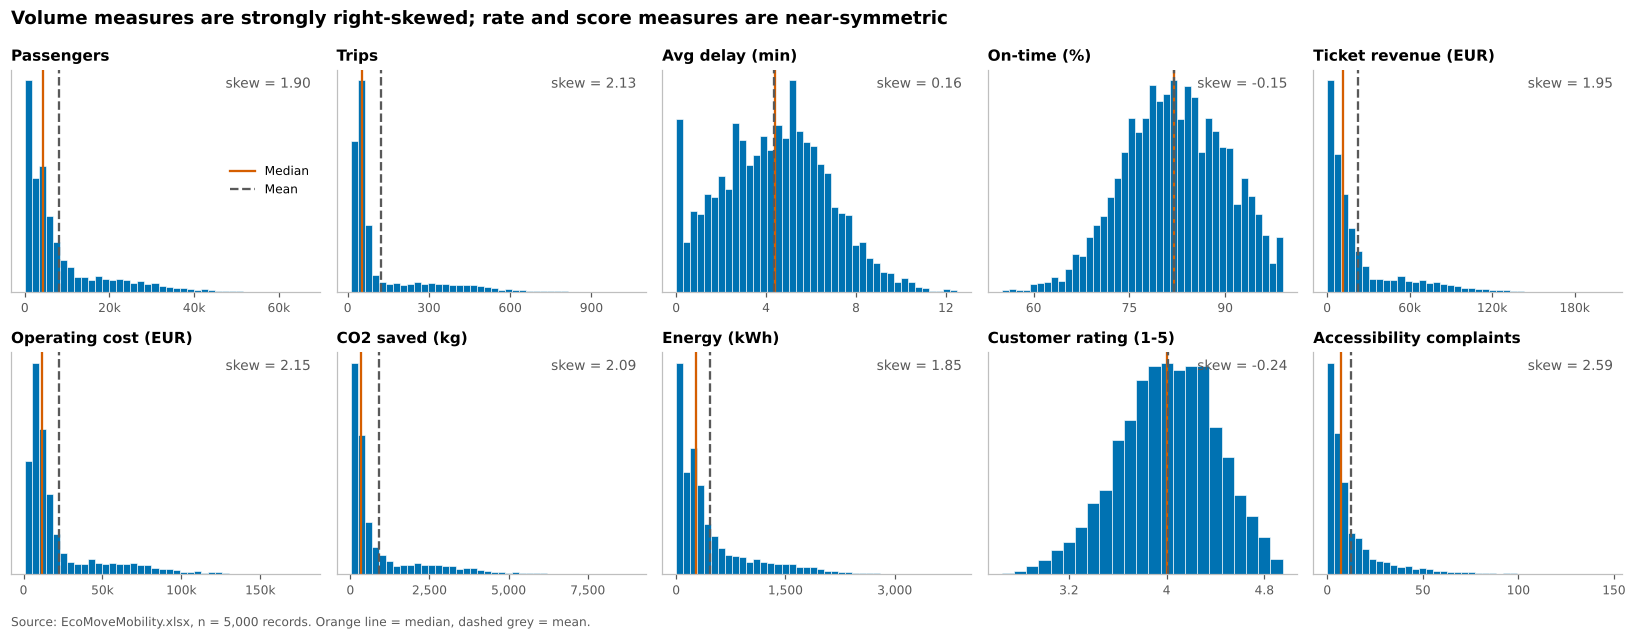

In [32]:
fig = plot_numeric_distributions(data)
show_figure(fig, 'EDA1_numeric_distributions')

In [33]:
def plot_outliers_by_mode(df: pd.DataFrame, col: str = "Passengers") -> plt.Figure:
    """Box plot by mode on a log axis, with the pooled IQR upper fence."""
    fig, ax = plt.subplots(figsize=(9, 4.6))
    modes = MODE_ORDER
    data = [df.loc[df["Transport_Mode"] == m, col] for m in modes]
    bp = ax.boxplot(data, vert=False, tick_labels=modes, patch_artist=True, widths=0.6,
                    flierprops=dict(marker="o", markersize=3, alpha=0.4, markeredgewidth=0),
                    medianprops=dict(color="black", lw=1.5))
    for patch, flier, m in zip(bp["boxes"], bp["fliers"], modes):
        patch.set_facecolor(MODE_COLOURS[m])
        patch.set_alpha(0.85)
        patch.set_edgecolor("white")
        flier.set_markerfacecolor(MODE_COLOURS[m])
    _, hi = iqr_bounds(df[col])
    pooled_share = (df[col] > hi).mean() * 100
    metro_share = (df.loc[df[col] > hi, "Transport_Mode"] == "Metro").mean() * 100
    ax.axvline(hi, color=NEUTRAL, ls="--", lw=1.2)
    ax.text(hi * 1.05, 5.45, f"Pooled IQR upper fence ({hi:,.0f})\n"
            f"{pooled_share:.1f}% of records above it; {metro_share:.0f}% of those are Metro",
            fontsize=8.5, color=NEUTRAL, va="center")
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
    ax.invert_yaxis()
    ax.grid(axis="x", color="#E6E6E6")
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(f"{LABELS[col]} per record (log scale)")
    ax.set_title("Most passenger 'outliers' are busy Metro records, not errors")
    fig.text(0.01, -0.03, "Source: EcoMoveMobility.xlsx. Boxes = IQR, line = median, "
             "whiskers = 1.5 x IQR within mode.", fontsize=8, color=NEUTRAL)
    fig.tight_layout()
    return fig

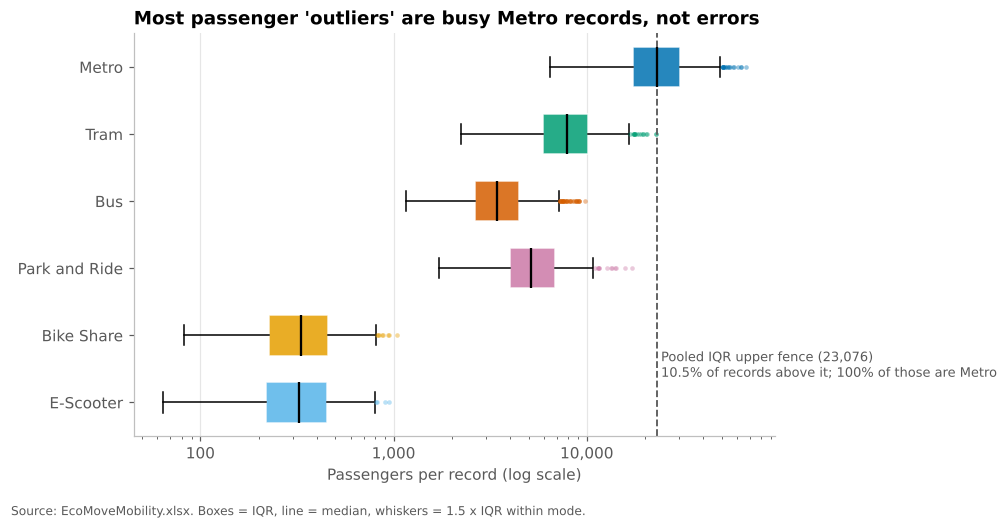

In [34]:
fig = plot_outliers_by_mode(data)
show_figure(fig, 'EDA2_outliers_by_mode')

In [35]:
def plot_record_counts(monthly: pd.DataFrame) -> plt.Figure:
    """Records per month and indexed totals vs per-record means (one y-scale per panel)."""
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                                   gridspec_kw={"height_ratios": [1, 1.4]})
    x = monthly.index
    ax1.bar(x, monthly["Records"], width=20, color=LIGHT_NEUTRAL)
    ax1.axhline(monthly["Records"].mean(), color=NEUTRAL, lw=1, ls=":")
    ax1.set_ylabel("Records")
    ax1.set_title(f"(a) The number of records varies by month "
                  f"({monthly['Records'].min()}-{monthly['Records'].max()})")
    ax1.set_ylim(150, 240)

    base = monthly.loc[monthly.index.year == 2024]
    total_idx = 100 * monthly["Total_Passengers"] / base["Total_Passengers"].mean()
    mean_idx = 100 * monthly["Mean_Passengers_per_Record"] / base["Mean_Passengers_per_Record"].mean()
    ax2.plot(x, total_idx, color=HIGHLIGHT, lw=2, marker="o", ms=4)
    ax2.plot(x, mean_idx, color=BASE, lw=2, marker="o", ms=4)
    ax2.axhline(100, color=NEUTRAL, lw=0.8)
    # Direct labels, nudged apart so they never collide
    t_y, m_y = total_idx.iloc[-1], mean_idx.iloc[-1]
    gap = 4
    if abs(t_y - m_y) < gap:
        mid = (t_y + m_y) / 2
        t_y, m_y = (mid - gap / 2, mid + gap / 2) if t_y <= m_y else (mid + gap / 2, mid - gap / 2)
    ax2.text(x[-1] + pd.Timedelta(days=12), t_y, "Total passengers",
             color=HIGHLIGHT, va="center", fontsize=9)
    ax2.text(x[-1] + pd.Timedelta(days=12), m_y, "Mean per record",
             color=BASE, va="center", fontsize=9)
    ax2.set_ylabel("Index (2024 average = 100)")
    ax2.set_title("(b) Totals depend on how many records a month has; the mean per record does not")
    ax2.xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax2.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b\n%Y"))
    fig.text(0.01, -0.02, "Source: EcoMoveMobility.xlsx. Each panel has its own single y-axis.",
             fontsize=8, color=NEUTRAL)
    fig.tight_layout()
    return fig

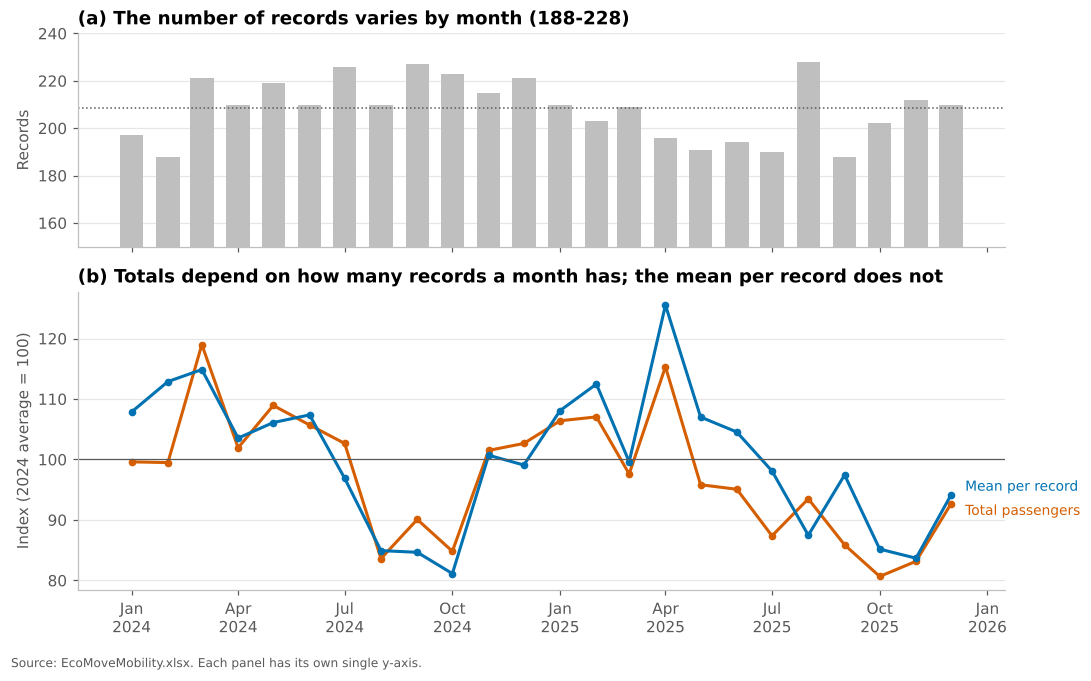

In [36]:
monthly = temporal_coverage(data)
fig = plot_record_counts(monthly)
show_figure(fig, 'EDA3_record_counts')

In [37]:
def plot_categorical_frequencies(freq: pd.DataFrame) -> plt.Figure:
    """Small multiples of category frequencies (single neutral hue: counts, not identity)."""
    variables = CATEGORICAL_COLS
    fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
    for ax, var in zip(axes.flat, variables):
        sub = freq[freq["Variable"] == var].sort_values("Records")
        ax.set_axisbelow(True)  # gridlines behind bars
        ax.barh(sub["Category"], sub["Records"], color=BASE, height=0.65)
        for y, (v, p) in enumerate(zip(sub["Records"], sub["% of records"])):
            ax.text(v + sub["Records"].max() * 0.01, y, f"{v:,} ({p:.1f}%)",
                    va="center", fontsize=8, color=NEUTRAL)
        ax.set_title(var.replace("_", " "), fontsize=10)
        ax.set_xlim(0, sub["Records"].max() * 1.35)
        ax.grid(axis="y", visible=False)
        ax.grid(axis="x", color="#EEEEEE")
        ax.tick_params(axis="y", labelsize=8.5)
    fig.suptitle("Category balance: cities and route types are evenly sampled; "
                 "mode, weather and event days are not", x=0.01, ha="left",
                 fontsize=12, fontweight="bold")
    fig.tight_layout()
    return fig

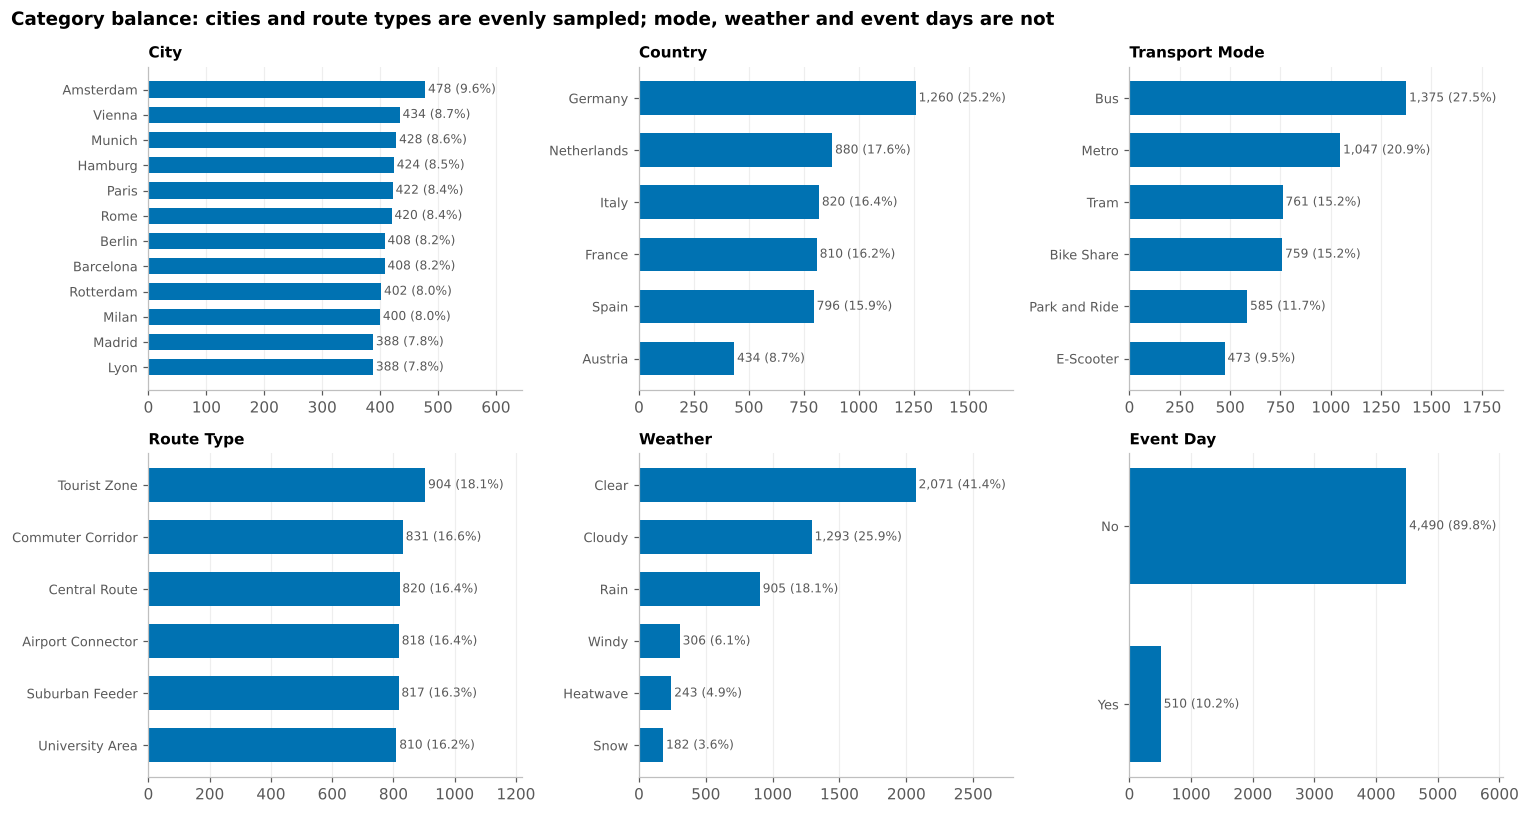

In [38]:
freq = categorical_frequency(data)
fig = plot_categorical_frequencies(freq)
show_figure(fig, 'EDA4_categorical_frequencies')

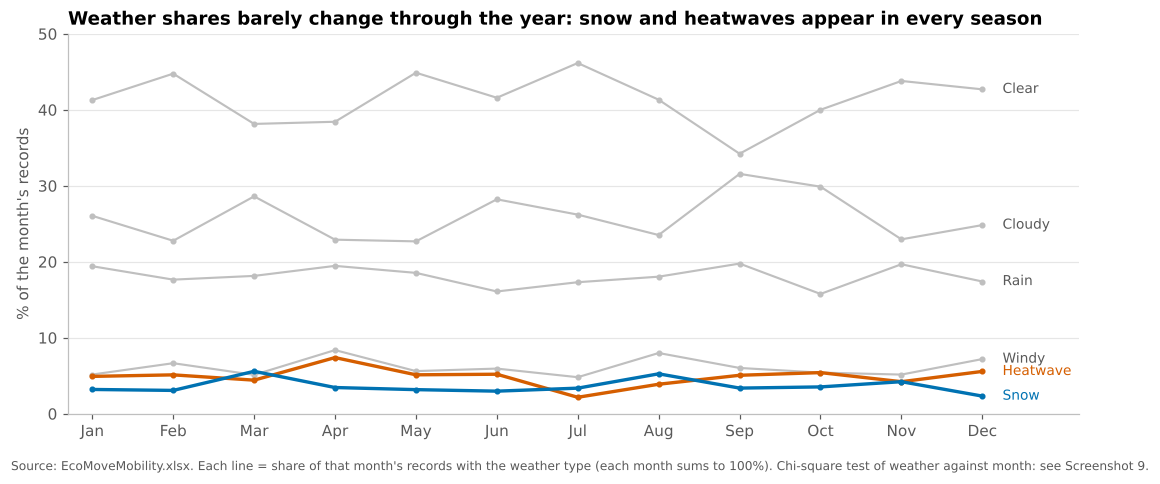

In [39]:
def plot_weather_by_month(df: pd.DataFrame) -> plt.Figure:
    """Share of each month's records by weather type (one line per weather type).

    Real weather would follow the seasons (snow in winter, heatwaves in summer);
    flat lines mean the weather labels do not follow the calendar.
    """
    tab = pd.crosstab(df["Month"], df["Weather"], normalize="index").reindex(columns=WEATHER_ORDER) * 100
    fig, ax = plt.subplots(figsize=(10, 4.2))
    highlight = {"Snow": BASE, "Heatwave": HIGHLIGHT}
    for w in WEATHER_ORDER:
        colour = highlight.get(w, LIGHT_NEUTRAL)
        ax.plot(tab.index, tab[w], color=colour, lw=2.2 if w in highlight else 1.4, marker="o", ms=3)
        ax.text(12.25, tab[w].iloc[-1], w, va="center", fontsize=9,
                color=colour if w in highlight else NEUTRAL)
    ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                                 "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
    ax.set_xlim(0.7, 13.2)
    ax.set_ylim(0, 50)
    ax.set_ylabel("% of the month's records")
    ax.set_title("Weather shares barely change through the year: snow and heatwaves appear in every season")
    fig.text(0.01, -0.03, "Source: EcoMoveMobility.xlsx. Each line = share of that month's records with "
             "the weather type (each month sums to 100%). Chi-square test of weather against month: see Screenshot 9.",
             fontsize=8, color=NEUTRAL)
    fig.tight_layout()
    return fig

fig = plot_weather_by_month(data)
show_figure(fig, 'EDA5_weather_by_month')

## 2.5 Statistical functions

Rank-based tests with effect sizes, bootstrap confidence intervals for pooled ratios, correlations and regression models. They are used by the tables and figures below.

**Settings and effect-size helpers**

In [40]:
RNG_SEED = RANDOM_SEED


N_BOOT = 2000


# Effect-size helpers
def epsilon_squared(h: float, n: int) -> float:
    """Kruskal-Wallis effect size: epsilon^2 = H / (n - 1)."""
    return h / (n - 1)


def describe_epsilon(e2: float) -> str:
    """Conventional labels for epsilon^2 (0.01 small, 0.08 medium, 0.26 large)."""
    if e2 < 0.01:
        return "negligible"
    if e2 < 0.08:
        return "small"
    if e2 < 0.26:
        return "medium"
    return "large"


def describe_r(r: float) -> str:
    """Labels for rank-biserial r (|r| 0.1 small, 0.3 medium, 0.5 large)."""
    a = abs(r)
    if a < 0.1:
        return "negligible"
    if a < 0.3:
        return "small"
    if a < 0.5:
        return "medium"
    return "large"

**Assumption checks and group comparisons**

In [41]:
# Assumption checks
def assumption_checks(df: pd.DataFrame, values: list[str], group: str = "Transport_Mode") -> pd.DataFrame:
    """Normality within groups (D'Agostino-Pearson) and equal variances
    (Brown-Forsythe / median-centred Levene) across groups."""
    rows = []
    for v in values:
        groups = [g[v].to_numpy() for _, g in df.groupby(group, observed=True)]
        normal_p = [stats.normaltest(g).pvalue for g in groups]
        lev = stats.levene(*groups, center="median")
        sds = [g.std(ddof=1) for g in groups]
        rows.append({
            "Variable": v, "Grouping": group,
            "Groups failing normality (p<0.05)": f"{sum(p < 0.05 for p in normal_p)} of {len(groups)}",
            "Brown-Forsythe W": lev.statistic, "Brown-Forsythe p": lev.pvalue,
            "Largest/smallest group SD": max(sds) / min(sds),
            "Implication": "Use rank-based tests" if (lev.pvalue < 0.05 or
                                                      any(p < 0.05 for p in normal_p))
            else "Parametric tests acceptable",
        })
    return pd.DataFrame(rows)


# Group comparisons
def kruskal_test(df: pd.DataFrame, value: str, group: str, label: str | None = None) -> dict:
    """Kruskal-Wallis H test with epsilon^2 effect size and group medians."""
    data = df[[value, group]].dropna()
    groups = {k: g[value].to_numpy() for k, g in data.groupby(group, observed=True)}
    h, p = stats.kruskal(*groups.values())
    e2 = epsilon_squared(h, len(data))
    medians = {k: np.median(v) for k, v in groups.items()}
    hi, lo = max(medians, key=medians.get), min(medians, key=medians.get)
    return {
        "Test": label or f"{value} ~ {group}", "n": len(data), "Groups": len(groups),
        "H": h, "df": len(groups) - 1, "p": p, "epsilon^2": e2,
        "Effect size": describe_epsilon(e2),
        "Highest median": f"{hi} ({medians[hi]:,.2f})", "Lowest median": f"{lo} ({medians[lo]:,.2f})",
    }


def kruskal_within(df: pd.DataFrame, value: str, group: str, stratum: str = "Transport_Mode") -> pd.DataFrame:
    """Repeat a Kruskal-Wallis test inside each stratum (e.g. each mode) so a
    confounder cannot create or mask the effect. Holm-adjusted p-values."""
    rows = [kruskal_test(sub, value, group, label=f"{value} ~ {group} | {s}")
            for s, sub in df.groupby(stratum, observed=True)]
    out = pd.DataFrame(rows)
    out["p (Holm)"] = multipletests(out["p"], method="holm")[1]
    return out


def dunn_posthoc(df: pd.DataFrame, value: str, group: str, order: list[str] | None = None) -> pd.DataFrame:
    """Pairwise Dunn tests with Holm correction (matrix of adjusted p-values)."""
    res = sp.posthoc_dunn(df, val_col=value, group_col=group, p_adjust="holm")
    if order:
        order = [o for o in order if o in res.index]
        res = res.loc[order, order]
    return res


def mann_whitney(a: np.ndarray, b: np.ndarray) -> tuple[float, float, float]:
    """Two-sided Mann-Whitney U. Returns (U, p, rank-biserial r); r > 0 means
    values in `a` tend to be larger than in `b`."""
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    r = 2 * u / (len(a) * len(b)) - 1
    return u, p, r


def event_day_tests(df: pd.DataFrame, values: list[str]) -> pd.DataFrame:
    """Event vs non-event days, tested within each transport mode (Holm-adjusted)."""
    rows = []
    for v in values:
        for mode, sub in df.groupby("Transport_Mode", observed=True):
            ev = sub.loc[sub["Is_Event_Day"], v].to_numpy()
            no = sub.loc[~sub["Is_Event_Day"], v].to_numpy()
            u, p, r = mann_whitney(ev, no)
            rows.append({
                "Variable": v, "Mode": mode, "n event": len(ev), "n non-event": len(no),
                "Median event": np.median(ev), "Median non-event": np.median(no),
                "Median change (%)": 100 * (np.median(ev) / np.median(no) - 1) if np.median(no) else np.nan,
                "U": u, "p": p, "Rank-biserial r": r, "Effect size": describe_r(r),
            })
    out = pd.DataFrame(rows)
    out["p (Holm)"] = multipletests(out["p"], method="holm")[1]
    return out

**Bootstrap confidence intervals and the mode scorecard**

In [42]:
# Bootstrap confidence intervals
def bootstrap_ratio_ci(num: np.ndarray, den: np.ndarray, scale: float = 1.0,
                       n_boot: int = N_BOOT, seed: int = RNG_SEED, alpha: float = 0.05):
    """Percentile bootstrap CI for a pooled ratio sum(num)/sum(den)."""
    num, den = np.asarray(num, float), np.asarray(den, float)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(num), size=(n_boot, len(num)))
    boots = num[idx].sum(axis=1) / den[idx].sum(axis=1) * scale
    est = num.sum() / den.sum() * scale
    lo, hi = np.quantile(boots, [alpha / 2, 1 - alpha / 2])
    return est, lo, hi


def bootstrap_mean_ci(x: np.ndarray, n_boot: int = N_BOOT, seed: int = RNG_SEED, alpha: float = 0.05):
    """Percentile bootstrap CI for a mean."""
    return bootstrap_ratio_ci(x, np.ones_like(np.asarray(x, float)), n_boot=n_boot, seed=seed, alpha=alpha)


def grouped_ratio_ci(df: pd.DataFrame, by, num: str, den: str | None = None,
                     scale: float = 1.0) -> pd.DataFrame:
    """Pooled ratio (or mean, if den is None) with bootstrap CI for each group."""
    rows = []
    for key, g in df.groupby(by, observed=True):
        d = g[den].to_numpy() if den else np.ones(len(g))
        est, lo, hi = bootstrap_ratio_ci(g[num].to_numpy(), d, scale=scale)
        key = key if isinstance(key, tuple) else (key,)
        rows.append((*key, len(g), est, lo, hi))
    cols = ([by] if isinstance(by, str) else list(by)) + ["n", "Estimate", "CI low", "CI high"]
    return pd.DataFrame(rows, columns=cols)


def mode_scorecard(df: pd.DataFrame) -> pd.DataFrame:
    """Headline KPIs per mode with 95% bootstrap CIs (long format)."""
    specs = [
        ("Revenue / cost (pooled)", "Ticket_Revenue_EUR", "Operating_Cost_EUR", 1),
        ("Mean delay (min)", "Average_Delay_Minutes", None, 1),
        ("Mean customer rating", "Customer_Rating", None, 1),
        ("Complaints per 10k passengers", "Accessibility_Complaints", "Passengers", 10_000),
        ("CO2 saved per passenger (kg)", "CO2_Saved_KG", "Passengers", 1),
        ("Net cost per passenger (EUR)", "Net_Cost_EUR", "Passengers", 1),
        ("Energy per passenger (kWh)", "Energy_Consumption_KWh", "Passengers", 1),
    ]
    d = df.assign(Net_Cost_EUR=df["Operating_Cost_EUR"] - df["Ticket_Revenue_EUR"])
    frames = []
    for name, num, den, scale in specs:
        t = grouped_ratio_ci(d, "Transport_Mode", num, den, scale)
        t.insert(0, "KPI", name)
        frames.append(t)
    return pd.concat(frames, ignore_index=True)

**Correlations**

In [43]:
# Correlation
def spearman_matrix(df: pd.DataFrame, cols: list[str]) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Spearman rho and p-value matrices."""
    rho, p = stats.spearmanr(df[cols].to_numpy())
    return (pd.DataFrame(rho, index=cols, columns=cols),
            pd.DataFrame(p, index=cols, columns=cols))


def within_mode_correlations(df: pd.DataFrame, pairs: list[tuple[str, str]]) -> pd.DataFrame:
    """Spearman rho for each pair, pooled and within each mode. If the pooled
    value is much larger than the within-mode values, mode differences (not a
    record-level relationship) are driving the pooled correlation."""
    rows = []
    for x, y in pairs:
        rows.append({"Pair": f"{x} vs {y}", "Mode": "All (pooled)", "n": len(df),
                     "rho": stats.spearmanr(df[x], df[y])[0]})
        for mode, sub in df.groupby("Transport_Mode", observed=True):
            rows.append({"Pair": f"{x} vs {y}", "Mode": mode, "n": len(sub),
                         "rho": stats.spearmanr(sub[x], sub[y])[0]})
    return pd.DataFrame(rows)


def within_mode_range(df: pd.DataFrame, cols: list[str]) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Smallest and largest Spearman rho across the six modes for every pair.
    Shown beside the pooled value so readers can see which relationships
    survive once differences between modes are removed."""
    mats = [g[cols].corr(method="spearman") for _, g in df.groupby("Transport_Mode", observed=True)]
    stack = np.stack([m.values for m in mats])
    return (pd.DataFrame(stack.min(axis=0), index=cols, columns=cols),
            pd.DataFrame(stack.max(axis=0), index=cols, columns=cols))

**Regression models, city demand index and event uplift**

In [44]:
# Regression models (descriptive adjustment for confounding)
DEMAND_FORMULA = (
    "np.log(Passengers) ~ C(Transport_Mode, Treatment('Bus')) + C(City)"
    " + C(Route_Type, Treatment('Central Route')) + C(Weather, Treatment('Clear'))"
    " + Is_Event_Day + C(Month) + C(Weekday, Treatment('Mon'))"
)


DELAY_FORMULA = (
    "Average_Delay_Minutes ~ C(Transport_Mode, Treatment('Bus')) + C(City)"
    " + C(Route_Type, Treatment('Central Route')) + C(Weather, Treatment('Clear'))"
    " + Is_Event_Day + C(Month) + C(Weekday, Treatment('Mon'))"
)


RATING_FORMULA = (
    "Customer_Rating ~ Average_Delay_Minutes + C(Transport_Mode, Treatment('Bus'))"
    " + C(Weather, Treatment('Clear')) + Is_Event_Day"
)


def fit_ols(df: pd.DataFrame, formula: str):
    """OLS with HC3 heteroscedasticity-robust standard errors."""
    return smf.ols(formula, data=df).fit(cov_type="HC3")


def _clean_term(term: str) -> str:
    """'C(Weather, Treatment('Clear'))[T.Snow]' -> 'Weather: Snow'."""
    if term == "Intercept":
        return term
    if term.startswith("Is_Event_Day"):
        return "Event day: Yes"
    if term.startswith("C("):
        var = term[2:].split(",")[0].split(")")[0]
        level = term.split("[T.")[-1].rstrip("]")
        return f"{var.replace('_', ' ')}: {level}"
    return term.replace("_", " ")


def coefficient_table(model, log_outcome: bool = False) -> pd.DataFrame:
    """Coefficients with 95% CIs. For a log outcome, also the % effect
    (exp(b) - 1), i.e. the multiplicative change holding other terms fixed."""
    ci = model.conf_int()
    t = pd.DataFrame({
        "Term": [_clean_term(i) for i in model.params.index],
        "Coef": model.params.values, "CI low": ci[0].values, "CI high": ci[1].values,
        "p": model.pvalues.values,
    })
    if log_outcome:
        for c in ["Coef", "CI low", "CI high"]:
            t[f"% effect ({c})" if c != "Coef" else "% effect"] = 100 * (np.exp(t[c]) - 1)
    return t


def model_summary(model, name: str) -> dict:
    return {"Model": name, "n": int(model.nobs), "R-squared": model.rsquared,
            "Adj. R-squared": model.rsquared_adj, "Parameters": len(model.params),
            "SE type": model.cov_type}


def term_wald_tests(model, factors: list[str]) -> pd.DataFrame:
    """Joint Wald test that all levels of a factor are zero (e.g. 'does city
    matter once everything else is held constant?')."""
    rows = []
    names = model.params.index
    for f in factors:
        idx = [i for i, n in enumerate(names) if n.startswith(f"C({f}") or n.startswith(f)]
        if not idx:
            continue
        r = np.zeros((len(idx), len(names)))
        for row, col in enumerate(idx):
            r[row, col] = 1
        w = model.wald_test(r, scalar=True)
        rows.append({"Factor": f, "Levels tested": len(idx), "Wald chi2": float(w.statistic),
                     "p": float(w.pvalue)})
    return pd.DataFrame(rows)


def demand_index(df: pd.DataFrame, level: str = "City", n_boot: int = N_BOOT,
                 seed: int = RNG_SEED) -> pd.DataFrame:
    """Observed / expected passengers per city or country (indirect standardisation).

    'Expected' comes from a demand model *without* city, so it reflects each
    place's mix of modes, routes, weather, event days and calendar. An index
    of 1.10 means the place carries 10% more passengers than its service mix
    predicts. CIs bootstrap records within each place (model held fixed).
    """
    base = smf.ols(DEMAND_FORMULA.replace(" + C(City)", ""), data=df).fit()
    smear = np.mean(np.exp(base.resid))  # Duan smearing: unbiased back-transform
    expected = np.exp(base.fittedvalues) * smear
    d = df.assign(Expected=expected)
    rows = []
    for place, g in d.groupby(level, observed=True):
        est, lo, hi = bootstrap_ratio_ci(g["Passengers"].to_numpy(), g["Expected"].to_numpy(),
                                         n_boot=n_boot, seed=seed)
        rows.append({level: place, "Country": g["Country"].iloc[0], "n": len(g),
                     "Raw mean passengers": g["Passengers"].mean(),
                     "Index (obs/exp)": est, "CI low": lo, "CI high": hi})
    out = pd.DataFrame(rows).sort_values("Index (obs/exp)", ascending=False)
    return out.reset_index(drop=True)


def city_demand_index(df: pd.DataFrame, n_boot: int = N_BOOT, seed: int = RNG_SEED) -> pd.DataFrame:
    """City version of demand_index (kept for the code that calls it)."""
    return demand_index(df, "City", n_boot, seed)


def monthly_mode_index(df: pd.DataFrame) -> pd.DataFrame:
    """Mean passengers per record per mode-month, indexed to each mode's
    overall mean (=100), plus a centred 3-month rolling mean."""
    m = (df.groupby(["Transport_Mode", "Year_Month"], observed=True)["Passengers"]
         .agg(["mean", "size"]).reset_index())
    overall = df.groupby("Transport_Mode", observed=True)["Passengers"].mean()
    m["Index"] = 100 * m["mean"] / m["Transport_Mode"].map(overall).astype(float)
    m["Index (3-month rolling)"] = (m.groupby("Transport_Mode", observed=True)["Index"]
                                    .transform(lambda s: s.rolling(3, center=True, min_periods=2).mean()))
    return m.rename(columns={"mean": "Mean passengers", "size": "Records"})


def event_uplift(df: pd.DataFrame) -> pd.DataFrame:
    """Per mode: mean passengers and delay on event vs non-event days."""
    g = (df.groupby(["Transport_Mode", "Event_Day"], observed=True)
         [["Passengers", "Average_Delay_Minutes", "Customer_Rating"]].mean().unstack())
    out = pd.DataFrame({
        "Passengers (no event)": g[("Passengers", "No")],
        "Passengers (event)": g[("Passengers", "Yes")],
        "Delay (no event)": g[("Average_Delay_Minutes", "No")],
        "Delay (event)": g[("Average_Delay_Minutes", "Yes")],
        "Rating (no event)": g[("Customer_Rating", "No")],
        "Rating (event)": g[("Customer_Rating", "Yes")],
    })
    out["Passenger uplift (%)"] = 100 * (out["Passengers (event)"] / out["Passengers (no event)"] - 1)
    out["Extra delay (min)"] = out["Delay (event)"] - out["Delay (no event)"]
    return out.reindex(MODE_ORDER)

## 2.6 Assumption checks - justify the choice of tests

In [45]:
s01 = assumption_checks(data, ['Passengers', 'Average_Delay_Minutes', 'Customer_Rating',
                               'Complaints_per_10k_Pax'])
display(s01)

,Variable,Grouping,Groups failing normality (p<0.05),Brown-Forsythe W,Brown-Forsythe p,Largest/smallest group SD,Implication
0,Passengers,Transport_Mode,6 of 6,791.222,0.000,58.640,Use rank-based tests
1,Average_Delay_Minutes,Transport_Mode,6 of 6,5.722,0.000,1.268,Use rank-based tests
2,Customer_Rating,Transport_Mode,6 of 6,2.156,0.056,1.112,Use rank-based tests
3,Complaints_per_10k_Pax,Transport_Mode,6 of 6,274.877,0.000,4.765,Use rank-based tests


## 2.7 Omnibus group comparisons (Kruskal-Wallis, pooled)

In [46]:
tests = [
    ('Passengers', 'Transport_Mode'), ('Average_Delay_Minutes', 'Transport_Mode'),
    ('Customer_Rating', 'Transport_Mode'), ('Revenue_Cost_Ratio', 'Transport_Mode'),
    ('Complaints_per_10k_Pax', 'Transport_Mode'), ('Average_Delay_Minutes', 'Weather'),
    ('Customer_Rating', 'Weather'), ('Average_Delay_Minutes', 'City'),
    ('Average_Delay_Minutes', 'Route_Type'), ('Complaints_per_10k_Pax', 'Route_Type'),
]
s02 = pd.DataFrame([kruskal_test(data, v, g) for v, g in tests])
display(s02)

,Test,n,Groups,H,df,p,epsilon^2,Effect size,Highest median,Lowest median
0,Passengers ~ Transport_Mode,5000,6,"4,418.531",5,0.000,0.884,large,"Metro (23,119.00)",E-Scooter (323.00)
1,Average_Delay_Minutes ~ Transport_Mode,5000,6,"2,973.497",5,0.000,0.595,large,Bus (6.50),Bike Share (1.50)
2,Customer_Rating ~ Transport_Mode,5000,6,"1,560.850",5,0.000,0.312,large,Bike Share (4.40),Bus (3.80)
3,Revenue_Cost_Ratio ~ Transport_Mode,5000,6,"3,502.571",5,0.000,0.701,large,Park and Ride (1.21),Bike Share (0.05)
4,Complaints_per_10k_Pax ~ Transport_Mode,5000,6,116.683,5,0.000,0.023,small,Bus (18.00),Metro (14.68)
5,Average_Delay_Minutes ~ Weather,5000,6,677.754,5,0.000,0.136,medium,Snow (8.45),Clear (3.70)
6,Customer_Rating ~ Weather,5000,6,"1,305.623",5,0.000,0.261,large,Clear (4.20),Snow (3.30)
7,Average_Delay_Minutes ~ City,5000,12,13.549,11,0.259,0.003,negligible,Lyon (4.80),Milan (4.00)
8,Average_Delay_Minutes ~ Route_Type,5000,6,1.403,5,0.924,0.000,negligible,University Area (4.50),Commuter Corridor (4.30)
9,Complaints_per_10k_Pax ~ Route_Type,5000,6,378.212,5,0.000,0.076,small,Suburban Feeder (22.34),Airport Connector (14.67)


## 2.8 Stratified tests - effects within each transport mode

In [47]:
s03 = pd.concat([
    kruskal_within(data, 'Average_Delay_Minutes', 'Weather'),
    kruskal_within(data, 'Passengers', 'City'),
    kruskal_within(data, 'Complaints_per_10k_Pax', 'Route_Type'),
], ignore_index=True)
display(s03[['Test', 'n', 'H', 'p (Holm)', 'epsilon^2', 'Effect size', 'Highest median', 'Lowest median']])

,Test,n,H,p (Holm),epsilon^2,Effect size,Highest median,Lowest median
0,Average_Delay_Minutes ~ Weather | Metro,1047,325.585,0.000,0.311,large,Snow (7.65),Clear (3.00)
1,Average_Delay_Minutes ~ Weather | Tram,761,235.432,0.000,0.310,large,Snow (8.90),Clear (4.00)
2,Average_Delay_Minutes ~ Weather | Bus,1375,415.818,0.000,0.303,large,Snow (10.40),Clear (5.90)
3,Average_Delay_Minutes ~ Weather | Park and Ride,585,179.089,0.000,0.307,large,Snow (9.40),Clear (4.40)
4,Average_Delay_Minutes ~ Weather | Bike Share,759,187.763,0.000,0.248,medium,Snow (4.65),Clear (1.00)
5,Average_Delay_Minutes ~ Weather | E-Scooter,473,146.767,0.000,0.311,large,Snow (5.00),Clear (1.00)
6,Passengers ~ City | Metro,1047,129.240,0.000,0.124,medium,"Berlin (30,739.00)","Lyon (19,444.00)"
7,Passengers ~ City | Tram,761,159.730,0.000,0.210,medium,"Paris (10,680.00)","Rotterdam (5,482.00)"
8,Passengers ~ City | Bus,1375,217.355,0.000,0.158,medium,"Paris (4,809.00)","Rotterdam (2,721.50)"
9,Passengers ~ City | Park and Ride,585,88.782,0.000,0.152,medium,"Paris (7,615.00)","Rotterdam (4,300.50)"


In [48]:
s04 = dunn_posthoc(data, 'Average_Delay_Minutes', 'Weather', WEATHER_ORDER)
print('Dunn post-hoc, Holm-adjusted p-values (delay by weather):')
display(s04)

Dunn post-hoc, Holm-adjusted p-values (delay by weather):


,Clear,Cloudy,Windy,Rain,Heatwave,Snow
Clear,1.000,0.057,0.000,0.000,0.000,0.000
Cloudy,0.057,1.000,0.000,0.000,0.000,0.000
Windy,0.000,0.000,1.000,0.015,0.949,0.000
Rain,0.000,0.000,0.015,1.000,0.020,0.000
Heatwave,0.000,0.000,0.949,0.020,1.000,0.000
Snow,0.000,0.000,0.000,0.000,0.000,1.000


## 2.9 Event days vs non-event days (Mann-Whitney U within each mode)

In [49]:
s05 = event_day_tests(data, ['Passengers', 'Average_Delay_Minutes', 'Customer_Rating'])
display(s05[['Variable', 'Mode', 'n event', 'Median event', 'Median non-event', 'Median change (%)',
     'Rank-biserial r', 'Effect size', 'p (Holm)']])

,Variable,Mode,n event,Median event,Median non-event,Median change (%),Rank-biserial r,Effect size,p (Holm)
0,Passengers,Metro,95,"29,370.000","22,610.500",29.895,0.365,medium,0.000
1,Passengers,Tram,89,"9,338.000","7,836.000",19.168,0.293,small,0.000
2,Passengers,Bus,147,"4,039.000","3,334.000",21.146,0.333,medium,0.000
3,Passengers,Park and Ride,64,"6,873.500","4,999.000",37.497,0.371,medium,0.000
4,Passengers,Bike Share,65,428.000,323.000,32.508,0.342,medium,0.000
5,Passengers,E-Scooter,50,392.500,317.000,23.817,0.287,small,0.003
6,Average_Delay_Minutes,Metro,95,4.500,3.500,28.571,0.440,medium,0.000
7,Average_Delay_Minutes,Tram,89,5.600,4.600,21.739,0.386,medium,0.000
8,Average_Delay_Minutes,Bus,147,7.400,6.300,17.460,0.410,medium,0.000
9,Average_Delay_Minutes,Park and Ride,64,6.200,4.900,26.531,0.500,medium,0.000


In [50]:
uplift = event_uplift(data)
display(uplift)

,Passengers (no event),Passengers (event),Delay (no event),Delay (event),Rating (no event),Rating (event),Passenger uplift (%),Extra delay (min)
Transport_Mode,,,,,,,,
Metro,"23,873.887","31,890.337",3.624,4.819,4.108,3.938,33.578,1.194
Tram,"8,133.263","10,284.551",4.659,5.796,3.959,3.819,26.450,1.137
Bus,"3,585.250","4,562.633",6.463,7.552,3.754,3.622,27.261,1.089
Park and Ride,"5,379.868","7,223.578",5.006,6.461,3.917,3.780,34.271,1.455
Bike Share,343.349,468.938,1.532,2.506,4.356,4.278,36.578,0.974
E-Scooter,337.589,422.840,1.793,3.188,4.310,4.150,25.253,1.395


## 2.10 KPI scorecard by mode with 95% bootstrap CIs

In [51]:
scorecard = mode_scorecard(data)
display(scorecard.pivot(index='Transport_Mode', columns='KPI', values='Estimate').reindex(MODE_ORDER))

KPI,CO2 saved per passenger (kg),Complaints per 10k passengers,Energy per passenger (kWh),Mean customer rating,Mean delay (min),Net cost per passenger (EUR),Revenue / cost (pooled)
Transport_Mode,,,,,,,
Metro,0.122,14.846,0.056,4.092,3.733,-0.167,1.062
Tram,0.101,15.078,0.061,3.943,4.792,-0.362,1.173
Bus,0.082,17.462,0.076,3.740,6.579,-0.002,1.001
Park and Ride,0.061,15.873,0.036,3.902,5.165,-0.546,1.215
Bike Share,0.183,17.004,0.000,4.349,1.615,20.843,0.052
E-Scooter,0.132,18.360,0.018,4.293,1.940,19.981,0.074


## 2.11 Correlations - pooled and within mode

In [52]:
rho, rho_p = spearman_matrix(data, NUMERIC_COLS)
pairs = [('Average_Delay_Minutes', 'Customer_Rating'), ('Passengers', 'Accessibility_Complaints'),
         ('Passengers', 'Average_Delay_Minutes'), ('Passengers', 'Operating_Cost_EUR')]
s07 = within_mode_correlations(data, pairs)
display(s07.pivot(index='Pair', columns='Mode', values='rho'))

Mode,All (pooled),Bike Share,Bus,E-Scooter,Metro,Park and Ride,Tram
Pair,,,,,,,
Average_Delay_Minutes vs Customer_Rating,-0.806,-0.633,-0.700,-0.703,-0.703,-0.692,-0.722
Passengers vs Accessibility_Complaints,0.911,0.402,0.505,0.341,0.578,0.546,0.583
Passengers vs Average_Delay_Minutes,0.205,0.006,-0.057,-0.085,-0.120,-0.109,-0.089
Passengers vs Operating_Cost_EUR,0.902,0.782,0.975,0.775,0.980,0.975,0.976


## 2.12 Regression models (descriptive adjustment for confounding; HC3 robust SEs)

In [53]:
demand = fit_ols(data, DEMAND_FORMULA)
delay = fit_ols(data, DELAY_FORMULA)
rating = fit_ols(data, RATING_FORMULA)
s08 = pd.DataFrame([model_summary(demand, 'log(Passengers)'),
                    model_summary(delay, 'Average delay (min)'),
                    model_summary(rating, 'Customer rating')])
display(s08)

,Model,n,R-squared,Adj. R-squared,Parameters,SE type
0,log(Passengers),5000,0.962,0.962,45,HC3
1,Average delay (min),5000,0.762,0.760,45,HC3
2,Customer rating,5000,0.739,0.738,13,HC3


In [54]:
s09 = coefficient_table(demand, log_outcome=True)
display(s09[['Term', '% effect', '% effect (CI low)', '% effect (CI high)', 'p']])

,Term,% effect,% effect (CI low),% effect (CI high),p
0,Intercept,"421,000.134","398,953.098","444,265.233",0.000
1,Transport Mode: Metro,565.227,551.447,579.299,0.000
2,Transport Mode: Tram,127.958,122.782,133.253,0.000
3,Transport Mode: Park and Ride,48.649,44.949,52.444,0.000
4,Transport Mode: Bike Share,-90.939,-91.233,-90.636,0.000
5,Transport Mode: E-Scooter,-91.042,-91.408,-90.660,0.000
6,City: Barcelona,20.766,15.796,25.949,0.000
7,City: Berlin,46.513,40.710,52.556,0.000
8,City: Hamburg,6.210,2.038,10.552,0.003
9,City: Lyon,-1.152,-5.087,2.947,0.576


In [55]:
print('Joint Wald tests (demand model):')
display(term_wald_tests(demand, ['City', 'Route_Type', 'Weather', 'Month', 'Weekday']))

Joint Wald tests (demand model):


,Factor,Levels tested,Wald chi2,p
0,City,11,"1,327.725",0.000
1,Route_Type,5,"1,170.908",0.000
2,Weather,5,490.438,0.000
3,Month,11,315.955,0.000
4,Weekday,6,974.514,0.000


In [56]:
s10 = coefficient_table(delay)
print('Joint Wald tests (delay model):')
display(term_wald_tests(delay, ['City', 'Route_Type', 'Weather', 'Month', 'Weekday']))
display(s10[['Term', 'Coef', 'CI low', 'CI high', 'p']])

Joint Wald tests (delay model):


,Factor,Levels tested,Wald chi2,p
0,City,11,9.249,0.599
1,Route_Type,5,1.975,0.853
2,Weather,5,"3,363.874",0.000
3,Month,11,6.768,0.818
4,Weekday,6,4.061,0.668


,Term,Coef,CI low,CI high,p
0,Intercept,5.836,5.632,6.040,0.000
1,Transport Mode: Metro,-2.869,-2.965,-2.772,0.000
2,Transport Mode: Tram,-1.834,-1.943,-1.725,0.000
3,Transport Mode: Park and Ride,-1.414,-1.528,-1.299,0.000
4,Transport Mode: Bike Share,-4.894,-4.993,-4.796,0.000
5,Transport Mode: E-Scooter,-4.678,-4.801,-4.556,0.000
6,City: Barcelona,-0.052,-0.209,0.106,0.521
7,City: Berlin,0.047,-0.114,0.209,0.566
8,City: Hamburg,0.033,-0.121,0.187,0.674
9,City: Lyon,0.061,-0.103,0.225,0.467


In [57]:
s11 = coefficient_table(rating)
display(s11[['Term', 'Coef', 'CI low', 'CI high', 'p']])

,Term,Coef,CI low,CI high,p
0,Intercept,4.604,4.573,4.635,0.000
1,Transport Mode: Metro,0.010,-0.012,0.031,0.384
2,Transport Mode: Tram,-0.009,-0.029,0.011,0.369
3,Transport Mode: Park and Ride,-0.012,-0.033,0.009,0.262
4,Transport Mode: Bike Share,0.006,-0.024,0.036,0.695
5,Transport Mode: E-Scooter,-0.002,-0.033,0.029,0.905
6,Weather: Cloudy,-0.010,-0.024,0.004,0.172
7,Weather: Windy,0.005,-0.021,0.030,0.718
8,Weather: Rain,-0.245,-0.263,-0.226,0.000
9,Weather: Heatwave,-0.248,-0.277,-0.219,0.000


**Shared chart text helpers** (titles, footers) used by every figure below

In [58]:
SOURCE = "Source: EcoMoveMobility.xlsx (n = 5,000 records, Jan 2024-Dec 2025)."


SHORT_LABELS = {
    "Passengers": "Passengers", "Trips": "Trips", "Average_Delay_Minutes": "Delay (min)",
    "On_Time_Percentage": "On-time %", "Ticket_Revenue_EUR": "Revenue",
    "Operating_Cost_EUR": "Operating cost", "CO2_Saved_KG": "CO2 saved",
    "Energy_Consumption_KWh": "Energy (kWh)", "Customer_Rating": "Rating",
    "Accessibility_Complaints": "Access. complaints",
}


def _titles(fig, title: str, subtitle: str, y: float = 1.0) -> None:
    """Title + subtitle anchored a fixed distance (in inches) from the top, so
    they never collide with each other or the plot whatever the figure height.
    (`y` is accepted for backward compatibility and ignored.)"""
    h = fig.get_figheight()
    fig.text(0.01, 1 - 0.12 / h, title, ha="left", va="top", fontsize=13, fontweight="bold")
    fig.text(0.01, 1 - 0.44 / h, subtitle, ha="left", va="top", fontsize=9.5, color=NEUTRAL)


def _footer(fig, note: str = "", y: float | None = None) -> None:
    h = fig.get_figheight()
    fig.text(0.01, 0.08 / h, f"{SOURCE} {note}".strip(), ha="left", va="bottom",
             fontsize=8, color=NEUTRAL)


def _finish(fig) -> None:
    """Fit the plotting area between the header (0.8 in) and footer (0.35 in)."""
    h = fig.get_figheight()
    fig.tight_layout(rect=(0, 0.35 / h, 1, 1 - 0.80 / h))

In [59]:
# Diagnostic - regression residuals (appendix)
def diag_regression_residuals(model, name: str) -> plt.Figure:
    """Residuals vs fitted and a normal Q-Q plot for a fitted OLS model."""
    from scipy import stats as st
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
    a1.scatter(model.fittedvalues, model.resid, s=5, alpha=0.3, color=BASE)
    a1.axhline(0, color=HIGHLIGHT, lw=1)
    a1.set_xlabel("Predicted value (log scale)")
    a1.set_ylabel("Residual (actual - predicted)")
    a1.set_title("(a) Residuals against predicted values: no pattern = good fit", fontsize=10)
    (osm, osr), (slope, intercept, _) = st.probplot(model.resid, dist="norm")
    a2.scatter(osm, osr, s=5, alpha=0.3, color=BASE)
    a2.plot(osm, slope * np.asarray(osm) + intercept, color=HIGHLIGHT, lw=1)
    a2.set_xlabel("Expected value if residuals were normal")
    a2.set_ylabel("Actual residual (sorted)")
    a2.set_title("(b) Q-Q plot: points on the line = normally distributed residuals", fontsize=10)
    fig.suptitle(f"Checking the {name}: it explains {model.rsquared:.0%} of the variation (R-squared)",
                 x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout()
    return fig

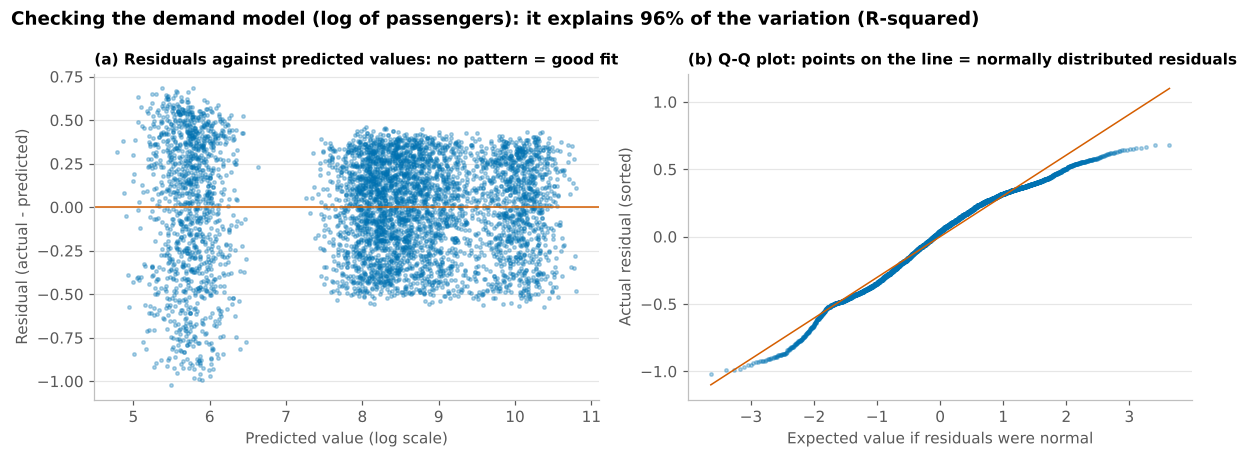

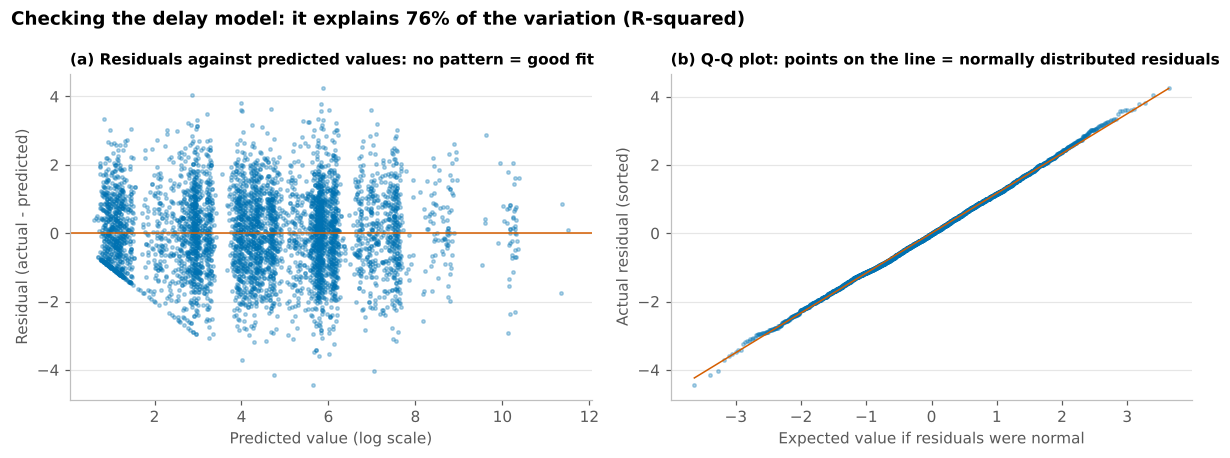

In [60]:
fig = diag_regression_residuals(demand, 'demand model (log of passengers)')
show_figure(fig, 'DIAG1_demand_model_residuals')
fig = diag_regression_residuals(delay, 'delay model')
show_figure(fig, 'DIAG2_delay_model_residuals')

## 2.13 City demand index and accessibility rates

In [61]:
s12 = city_demand_index(data)
display(s12)
s13 = demand_index(data, "Country")
display(s13)

,City,Country,n,Raw mean passengers,Index (obs/exp),CI low,CI high
0,Paris,France,422,"10,645.690",1.314,1.263,1.362
1,Berlin,Germany,408,"10,998.409",1.240,1.195,1.282
2,Madrid,Spain,388,"8,479.134",1.097,1.052,1.141
3,Barcelona,Spain,408,"8,642.941",1.016,0.981,1.053
4,Munich,Germany,428,"8,418.991",1.009,0.974,1.046
5,Rome,Italy,420,"8,139.586",1.009,0.972,1.047
6,Milan,Italy,400,"7,751.060",0.961,0.927,0.995
7,Hamburg,Germany,424,"7,085.292",0.904,0.871,0.936
8,Vienna,Austria,434,"7,807.535",0.864,0.833,0.894
9,Amsterdam,Netherlands,478,"7,038.519",0.859,0.831,0.885


,Country,n,Raw mean passengers,Index (obs/exp),CI low,CI high
0,France,810,"8,677.789",1.086,1.048,1.125
1,Germany,1260,"8,805.431",1.055,1.030,1.081
2,Spain,796,"8,563.095",1.053,1.024,1.082
3,Italy,820,"7,950.061",0.985,0.961,1.010
4,Austria,434,"7,807.535",0.864,0.833,0.894
5,Netherlands,880,"6,888.778",0.825,0.804,0.845


In [62]:
route_mode = grouped_ratio_ci(data, ['Route_Type', 'Transport_Mode'], 'Accessibility_Complaints',
                                'Passengers', scale=10_000)
route_all = grouped_ratio_ci(data, 'Route_Type', 'Accessibility_Complaints', 'Passengers', scale=10_000)
display(route_all)
display(route_mode.pivot(index='Route_Type', columns='Transport_Mode', values='Estimate').reindex(index=ROUTE_ORDER, columns=MODE_ORDER))

,Route_Type,n,Estimate,CI low,CI high
0,Central Route,820,14.703,13.998,15.399
1,Commuter Corridor,831,14.896,14.251,15.593
2,Airport Connector,818,14.912,14.139,15.643
3,Tourist Zone,904,15.561,14.858,16.192
4,University Area,810,15.598,14.901,16.271
5,Suburban Feeder,817,16.792,16.079,17.526


Transport_Mode,Metro,Tram,Bus,Park and Ride,Bike Share,E-Scooter
Route_Type,,,,,,
Central Route,14.308,14.198,16.893,15.611,12.307,12.991
Commuter Corridor,14.552,15.073,16.366,15.415,13.406,11.869
Airport Connector,14.356,15.660,16.639,15.708,10.933,13.236
Tourist Zone,15.562,14.845,16.823,15.394,13.957,13.239
University Area,15.488,14.366,17.859,15.559,14.197,14.213
Suburban Feeder,15.066,16.725,21.203,18.746,49.256,54.016


## 2.14 Main report figures

In [63]:
# Report figure - time series
def fig1_demand_time_series(monthly: pd.DataFrame, month_effects: pd.Series) -> plt.Figure:
    """Small multiples: monthly demand index per mode with 3-month rolling mean.

    monthly: output of analysis.monthly_mode_index
    month_effects: % effect by calendar month from the demand model (for the note)
    """
    fig, axes = plt.subplots(2, 3, figsize=(13, 6.4), sharex=True, sharey=True)
    for ax, mode in zip(axes.flat, MODE_ORDER):
        sub = monthly[monthly["Transport_Mode"] == mode]
        colour = MODE_COLOURS[mode]
        for year in (2024, 2025):  # shade Aug-Oct, the recurring trough
            ax.axvspan(pd.Timestamp(f"{year}-08-01"), pd.Timestamp(f"{year}-10-31"),
                       color="#F0F0F0", zorder=0)
        ax.axhline(100, color=LIGHT_NEUTRAL, lw=1, zorder=1)
        ax.plot(sub["Year_Month"], sub["Index"], color=colour, lw=0.8, alpha=0.45,
                marker="o", ms=2.5, zorder=2)
        ax.plot(sub["Year_Month"], sub["Index (3-month rolling)"], color=colour, lw=2.4, zorder=3)
        ax.set_title(mode, fontsize=11, color="black")
        ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
        ax.tick_params(labelsize=8.5)
    for ax in axes[:, 0]:
        ax.set_ylabel("Demand index\n(mode average = 100)")
    axes[0, 0].text(pd.Timestamp("2024-09-15"), 132, "Aug-Oct", ha="center", fontsize=8,
                    color=NEUTRAL)
    axes[0, 0].set_ylim(60, 140)
    oct_effect = month_effects.get(10, np.nan)
    apr_effect = month_effects.get(4, np.nan)
    _titles(fig, "Demand per record is usually higher in spring and lower in autumn; the pattern is weaker for some modes",
            "Mean passengers per record each month, indexed to each mode's two-year average "
            "(=100). Thin line = monthly value; thick line = centred 3-month rolling mean.")
    _footer(fig, f"Model-adjusted: April {apr_effect:+.0f}%, October {oct_effect:+.0f}% "
                 "vs January, holding mode, city, route, weather, event and weekday constant.")
    _finish(fig)
    return fig

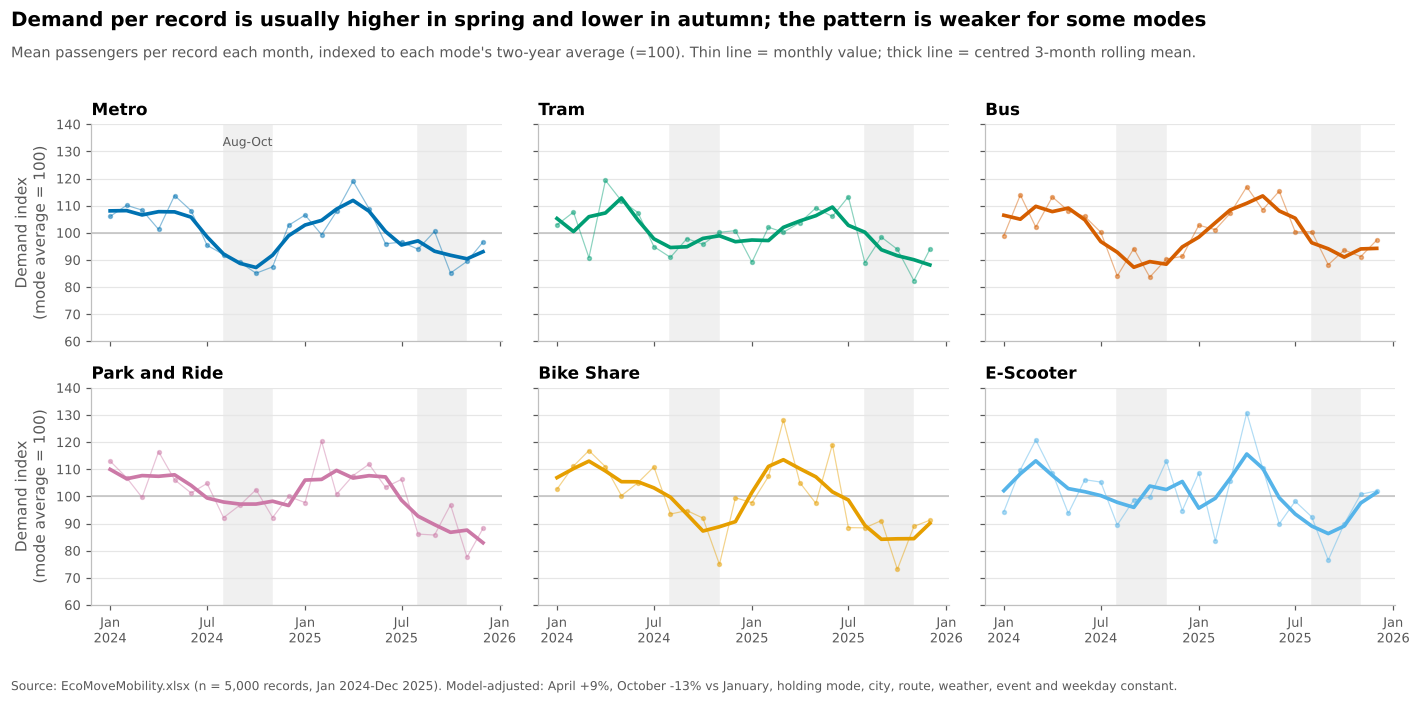

In [64]:
month_fx = s09[s09['Term'].str.startswith('Month')].set_index('Term')['% effect']
month_fx.index = [int(t.split(': ')[1]) for t in month_fx.index]
fig = fig1_demand_time_series(monthly_mode_index(data), month_fx)
show_figure(fig, 'Fig1_demand_time_series')

In [65]:
# Report figure - city and country comparison
ISO = {"France": "FR", "Germany": "DE", "Spain": "ES", "Italy": "IT",
       "Austria": "AT", "Netherlands": "NL"}  # ISO 3166-1 alpha-2


def _index_panel(ax, d: pd.DataFrame, labels: list[str], raw: pd.Series | None) -> None:
    """Dots with 95% CIs on a common scale; optional hollow dots for the unadjusted index."""
    y = np.arange(len(d))
    ax.axvline(1.0, color=NEUTRAL, lw=1)
    ax.hlines(y, d["CI low"], d["CI high"], color=BASE, lw=2.2, zorder=2)
    if raw is not None:
        ax.scatter(raw, y, s=55, facecolor="white", edgecolor=NEUTRAL, lw=1.3, zorder=3,
                   label="Unadjusted (mean per record / overall mean)")
    ax.scatter(d["Index (obs/exp)"], y, s=70, color=BASE, zorder=4,
               label="Adjusted for service mix, with 95% CI")
    for yi, (v, hi) in enumerate(zip(d["Index (obs/exp)"], d["CI high"])):
        right = max(hi, raw.iloc[yi]) if raw is not None else hi
        ax.text(right + 0.015, yi, f"{100 * (v - 1):+.0f}%", va="center", fontsize=9, color="black")
    ax.set_yticks(y, labels)
    ax.grid(axis="x", color="#E6E6E6")
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0.65, 1.45)


def fig2_city_comparison(city_idx: pd.DataFrame, overall_mean: float,
                         country_idx: pd.DataFrame | None = None) -> plt.Figure:
    """(a) cities and (b) countries: demand index adjusted for service mix, with 95% CIs."""
    d = city_idx.sort_values("Index (obs/exp)").reset_index(drop=True)
    raw = d["Raw mean passengers"] / overall_mean
    if country_idx is None:
        fig, ax = plt.subplots(figsize=(9.5, 6))
        axes = [ax]
    else:
        fig, axes = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1.5, 1]})
    _index_panel(axes[0], d, [f"{c} ({ISO.get(k, k)})" for c, k in zip(d["City"], d["Country"])], raw)
    axes[0].legend(loc="lower right", fontsize=8.5)
    axes[0].set_title("(a) Cities", fontsize=10.5)
    axes[0].set_xlabel("Demand index (1.0 = passengers expected for the service mix)")
    if country_idx is not None:
        c = country_idx.sort_values("Index (obs/exp)").reset_index(drop=True)
        _index_panel(axes[1], c, list(c["Country"]), None)
        axes[1].set_title("(b) Countries", fontsize=10.5)
        axes[1].set_xlabel("Demand index")
    _titles(fig, "After allowing for service mix, Paris and Berlin carry more passengers than expected; "
                 "Rotterdam and Lyon fewer",
            "Observed / expected passengers. Expected values come from a model without city "
            "(mode, route, weather, event day, month, weekday). Countries combine their cities.")
    _footer(fig, "CIs: 2,000 bootstrap resamples of records within each city or country. "
                 "Country codes: FR, DE, ES, IT, AT, NL.")
    _finish(fig)
    return fig

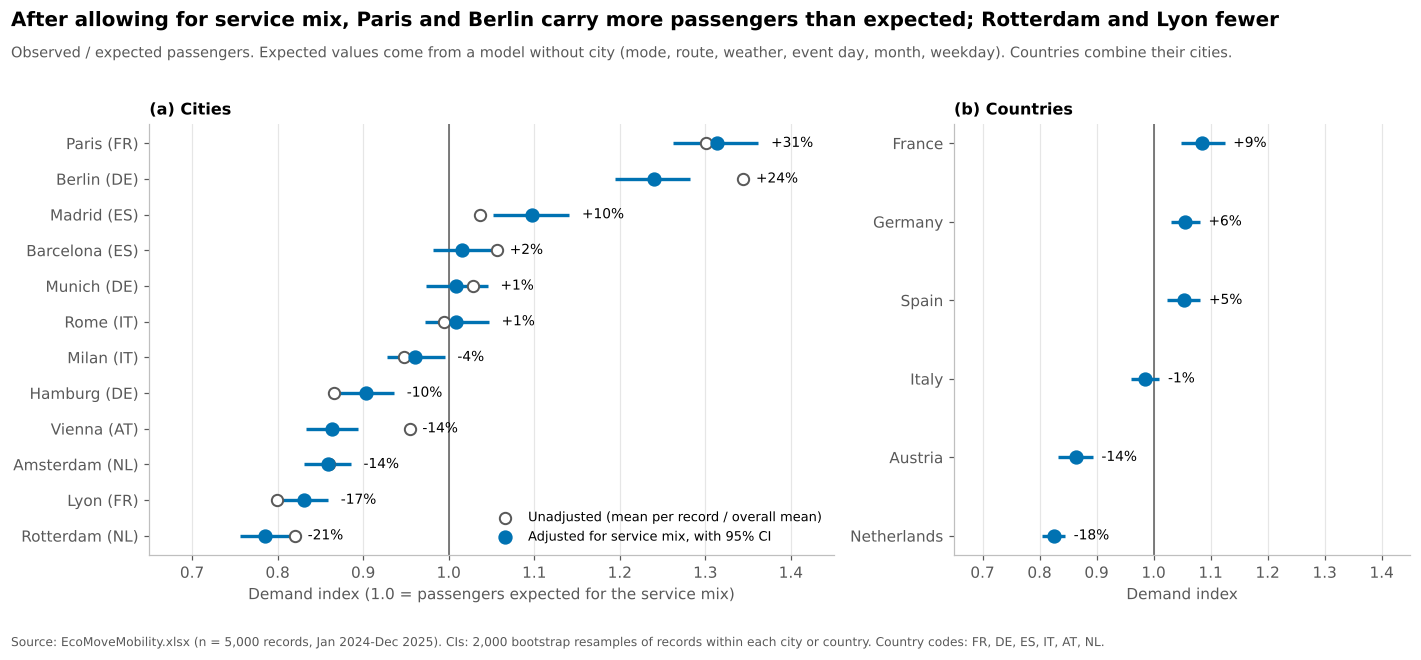

In [66]:
fig = fig2_city_comparison(s12, data['Passengers'].mean(), s13)
show_figure(fig, 'Fig2_city_comparison')

In [67]:
# Report figure - relationships
def fig3_correlation_heatmap(rho: pd.DataFrame, within_min: pd.DataFrame,
                             within_max: pd.DataFrame) -> plt.Figure:
    """Lower-triangle Spearman heatmap of the four decision measures.

    Each cell shows the pooled rho (large) and its range within the six
    transport modes (small), so mode-driven correlations are visible at once.
    Colour encodes the pooled value on a diverging scale centred on zero.
    """
    cols = list(rho.columns)
    labels = [DECISION_LABELS.get(c, c) for c in cols]
    n = len(cols)
    data = np.where(np.triu(np.ones((n, n), dtype=bool)), np.nan, rho.values)
    fig, ax = plt.subplots(figsize=(8.6, 6.6))
    im = ax.imshow(data, cmap="RdBu_r", vmin=-1, vmax=1)
    for i in range(n):
        for j in range(i):
            v = rho.values[i, j]
            lo, hi = within_min.values[i, j] + 0.0, within_max.values[i, j] + 0.0
            lo, hi = (0.0 if abs(lo) < 0.005 else lo), (0.0 if abs(hi) < 0.005 else hi)  # no "-0.00"
            colour = "white" if abs(v) > 0.55 else "black"
            ax.text(j, i - 0.12, f"{v:.2f}", ha="center", va="center", fontsize=19,
                    fontweight="bold", color=colour)
            ax.text(j, i + 0.22, f"within modes:\n{lo:.2f} to {hi:.2f}", ha="center", va="center",
                    fontsize=12.5, color=colour, linespacing=1.1)
    ax.set_xticks(range(n - 1), labels[:-1])
    ax.set_yticks(range(1, n), labels[1:])
    ax.set_xlim(-0.5, n - 1.5)
    ax.set_ylim(n - 0.5, 0.5)
    ax.tick_params(length=0, labelsize=12.5)
    ax.grid(False)
    for s_ in ax.spines.values():
        s_.set_visible(False)
    cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.03)
    cb.set_label("Pooled Spearman rank correlation (rho)")
    cb.outline.set_visible(False)
    _titles(fig, "Only delay and rating stay linked within every transport mode",
            "Large number = pooled Spearman rho; small text = range within the six modes.")
    _footer(fig, "Duplicates excluded: volume totals (rho 0.82-0.99), on-time % (rho -0.97 with delay).")
    _finish(fig)
    return fig

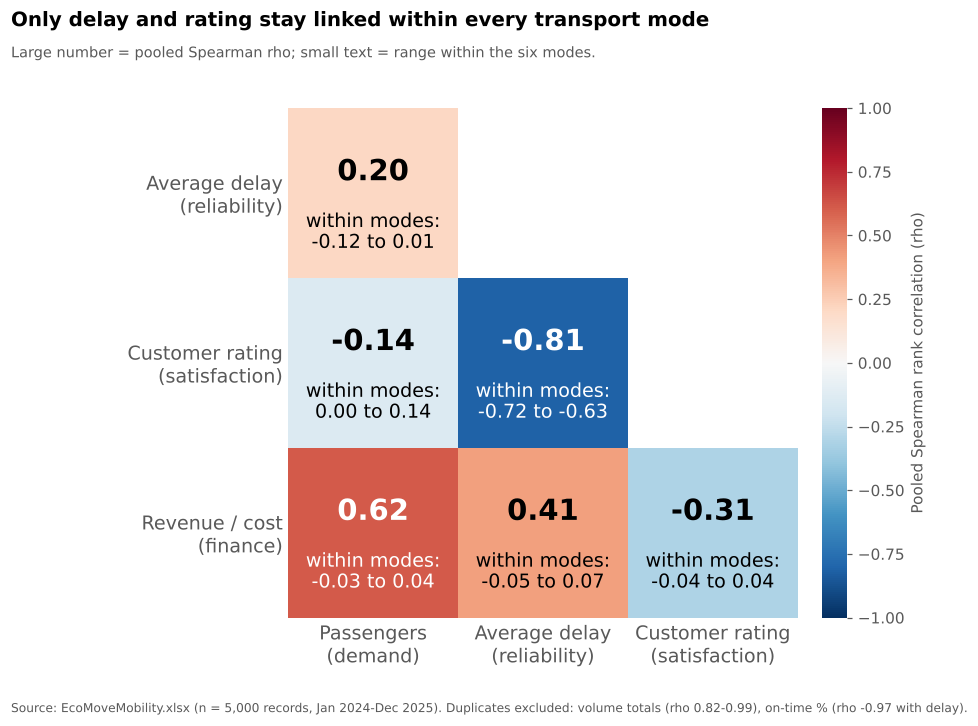

In [68]:
dv = DECISION_VARS
rho_dv, _ = spearman_matrix(data, dv)
wmin, wmax = within_mode_range(data, dv)
fig = fig3_correlation_heatmap(rho_dv, wmin, wmax)
show_figure(fig, 'Fig3_correlation_heatmap')

In [69]:
# Report figure - relationship in the raw records
def fig3b_delay_rating_scatter(df: pd.DataFrame, slope: float) -> plt.Figure:
    """One scatter panel per mode: every record's delay against its rating, with a straight-line fit."""
    fig, axes = plt.subplots(2, 3, figsize=(13, 6.6), sharex=True, sharey=True)
    for ax, mode in zip(axes.flat, MODE_ORDER):
        sub = df[df["Transport_Mode"] == mode]
        ax.scatter(sub["Average_Delay_Minutes"], sub["Customer_Rating"], s=6, alpha=0.25,
                   color=MODE_COLOURS[mode], linewidths=0)
        b, a = np.polyfit(sub["Average_Delay_Minutes"], sub["Customer_Rating"], 1)
        xs = np.linspace(sub["Average_Delay_Minutes"].min(), sub["Average_Delay_Minutes"].max(), 50)
        ax.plot(xs, a + b * xs, color="black", lw=1.6)
        rho_m = stats.spearmanr(sub["Average_Delay_Minutes"], sub["Customer_Rating"])[0]
        ax.text(0.97, 0.94, f"rho = {rho_m:.2f}\nn = {len(sub):,}", transform=ax.transAxes,
                ha="right", va="top", fontsize=8.5, color=NEUTRAL)
        ax.set_title(mode, fontsize=11, color="black")
        ax.grid(axis="both", color="#EEEEEE")
    for ax in axes[:, 0]:
        ax.set_ylabel("Customer rating (1-5)")
    for ax in axes[1, :]:
        ax.set_xlabel("Average delay (minutes)")
    _titles(fig, "In every mode, records with longer delays have lower customer ratings",
            "Each dot is one record; black line = straight-line fit within the mode. "
            "This shows an association, not proof that delay causes low ratings.")
    _footer(fig, f"Rating model (all modes, adjusted for mode, weather and event day): "
                 f"{slope:+.2f} rating points per extra minute of delay.")
    _finish(fig)
    return fig

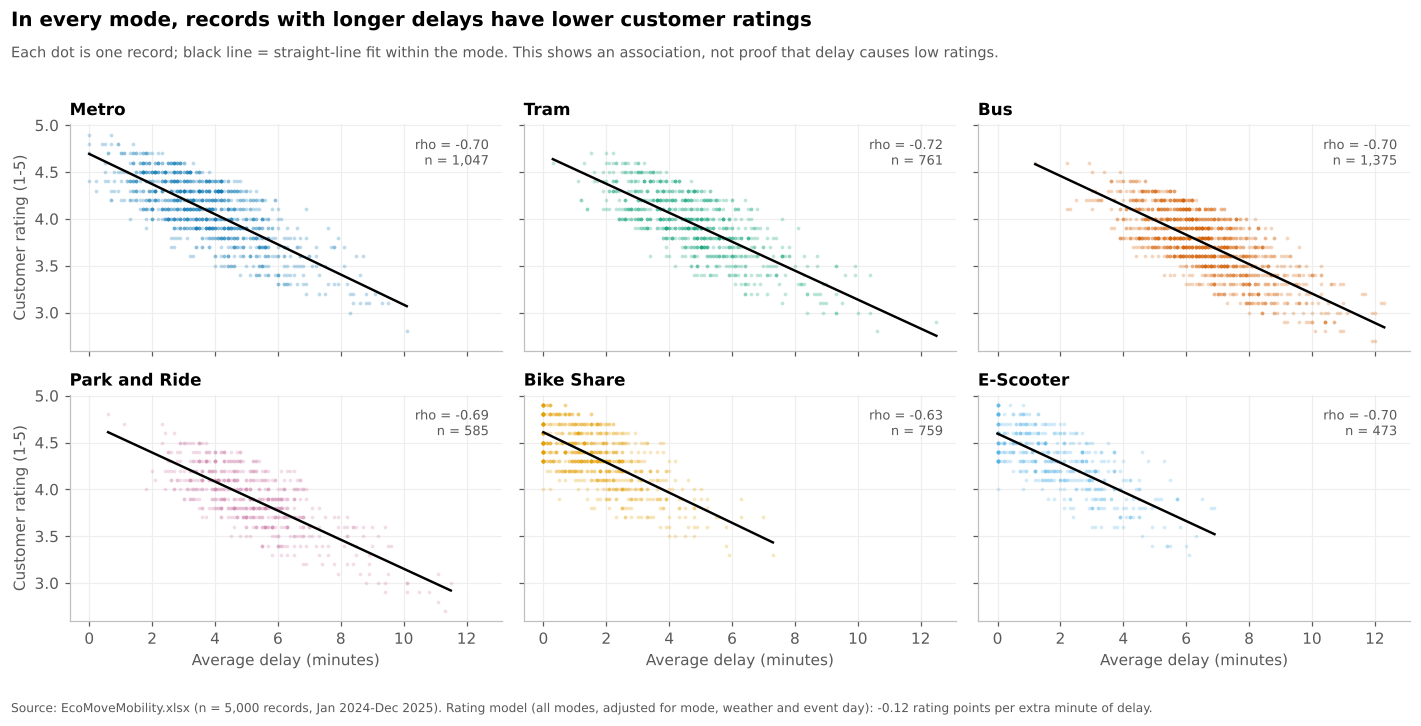

In [70]:
fig = fig3b_delay_rating_scatter(data, rating.params['Average_Delay_Minutes'])
show_figure(fig, 'Fig3b_delay_rating_scatter')

In [71]:
# Report figure - distribution
def fig4_delay_by_weather(df: pd.DataFrame, snow_effect: tuple[float, float, float]) -> plt.Figure:
    """Box plots of delay by weather, one panel per transport mode."""
    med_order = (df.groupby("Weather", observed=True)["Average_Delay_Minutes"].median()
                 .sort_values().index.tolist())
    fig, axes = plt.subplots(2, 3, figsize=(13, 7.2), sharex=True, sharey=True)
    for ax, mode in zip(axes.flat, MODE_ORDER):
        sub = df[df["Transport_Mode"] == mode]
        data_ = [sub.loc[sub["Weather"] == w, "Average_Delay_Minutes"] for w in med_order]
        bp = ax.boxplot(data_, vert=False, tick_labels=med_order, patch_artist=True, widths=0.6,
                        showfliers=True,
                        flierprops=dict(marker="o", ms=2.5, alpha=0.35, markeredgewidth=0,
                                        markerfacecolor=NEUTRAL),
                        medianprops=dict(color="black", lw=1.6),
                        whiskerprops=dict(color=NEUTRAL), capprops=dict(color=NEUTRAL))
        for patch, w in zip(bp["boxes"], med_order):
            patch.set_facecolor(HIGHLIGHT if w == "Snow" else "#C9D7E8")
            patch.set_edgecolor("white")
        for yi, d in enumerate(data_, start=1):
            ax.text(d.max() + 0.3, yi, f"{d.median():.1f}", va="center", fontsize=8, color=NEUTRAL)
        ax.set_title(mode, fontsize=11, color="black")
        ax.set_xlim(0, 17)
        ax.grid(axis="x", color="#E6E6E6")
        ax.grid(axis="y", visible=False)
    for ax in axes[1, :]:
        ax.set_xlabel("Average delay per record (minutes)")
    est, lo, hi = snow_effect
    _titles(fig, "Snow brings the longest delays in every mode; rain and heatwaves add smaller delays",
            "Average delay per record by weather, ordered by overall median. Boxes = middle 50% of records, "
            "line and number = median, whiskers = 1.5 x IQR.")
    _footer(fig, f"Model-adjusted snow effect vs clear: +{est:.2f} min (95% CI {lo:.2f}-{hi:.2f}). "
                 "Kruskal-Wallis within every mode: p < 0.001.")
    _finish(fig)
    return fig

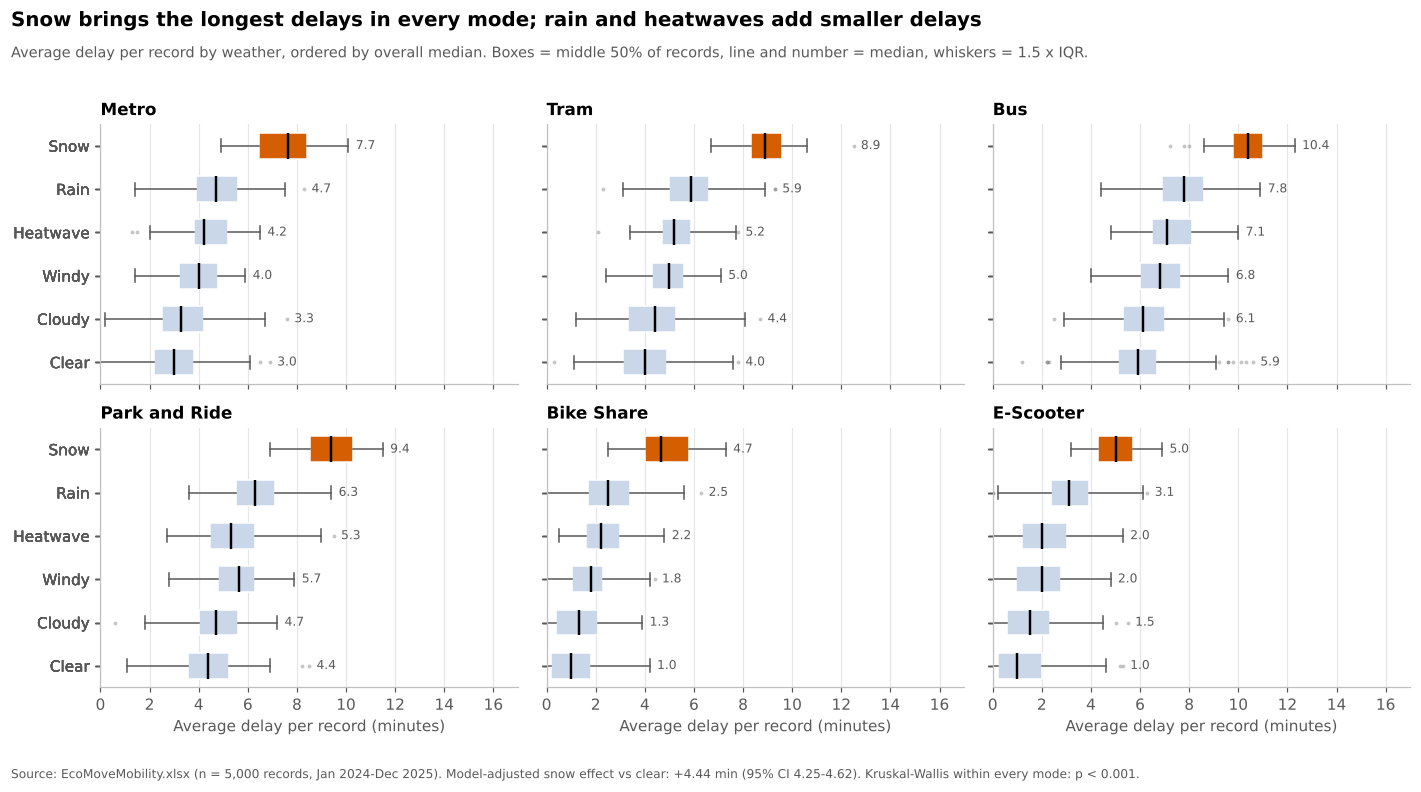

In [72]:
snow = s10.set_index('Term').loc['Weather: Snow']
fig = fig4_delay_by_weather(data, (snow['Coef'], snow['CI low'], snow['CI high']))
show_figure(fig, 'Fig4_delay_by_weather')

In [73]:
# Report figure - performance indicators
def fig5_mode_scorecard(scorecard: pd.DataFrame) -> plt.Figure:
    """Five small-multiple panels: cost recovery, delay, rating, CO2 and energy per passenger.

    Measures with a true zero use bars. Customer rating is on a 1-5 scale with no
    zero, so it uses dots on a narrow scale instead of bars.
    """
    panels = [
        ("Revenue / cost (pooled)", "Cost recovery\n(revenue / cost)", "{:.2f}", 1.0, "break-even"),
        ("Mean delay (min)", "Mean delay\n(minutes; lower is better)", "{:.1f}", None, None),
        ("Mean customer rating", "Mean customer rating\n(1-5 scale; dots)", "{:.2f}", None, None),
        ("CO2 saved per passenger (kg)", "CO2 saved per passenger\n(kg)", "{:.2f}", None, None),
        ("Energy per passenger (kWh)", "Energy used per passenger\n(kWh)", "{:.3f}", None, None),
    ]
    modes = MODE_ORDER
    fig, axes = plt.subplots(1, 5, figsize=(16.5, 4.9), sharey=True)
    for ax, (kpi, title, fmt, ref, ref_label) in zip(axes, panels):
        d = scorecard[scorecard["KPI"] == kpi].set_index("Transport_Mode").reindex(modes)
        y = np.arange(len(modes))
        err = np.vstack([d["Estimate"] - d["CI low"], d["CI high"] - d["Estimate"]])
        colours = [MODE_COLOURS[m] for m in modes]
        if kpi == "Mean customer rating":
            ax.errorbar(d["Estimate"], y, xerr=err, fmt="none", ecolor="black", lw=0.8, capsize=2, zorder=2)
            ax.scatter(d["Estimate"], y, s=80, color=colours, zorder=3)
            lo_x, hi_x = 3.5, 4.6
            for yi, v in enumerate(d["Estimate"]):
                ax.text(v + 0.05, yi, fmt.format(v), va="center", fontsize=9)
            ax.set_xlim(lo_x, hi_x)
        else:
            ax.barh(y, d["Estimate"], color=colours, height=0.62,
                    xerr=err, error_kw=dict(ecolor="black", lw=0.8, capsize=2))
            xmax = (d["CI high"].max()) * 1.35
            for yi, v in enumerate(d["Estimate"]):
                ax.text(v + xmax * 0.03, yi, fmt.format(v), va="center", fontsize=9)
            ax.set_xlim(0, xmax)
        if ref is not None:
            ax.axvline(ref, color="black", lw=1, ls="--")
            ax.text(ref + 0.03, len(modes) - 0.45, ref_label, ha="left", fontsize=8, color="black")
        ax.set_title(title, fontsize=10)
        ax.set_yticks(y, modes)
        ax.set_axisbelow(True)
        ax.grid(axis="x", color="#EEEEEE")
        ax.grid(axis="y", visible=False)
        ax.tick_params(axis="x", labelsize=8)
    axes[0].invert_yaxis()  # shared y: invert once so Metro sits at the top
    _titles(fig, "No mode does best on every measure: Bike Share and E-Scooter have the shortest delays "
                 "and best ratings but cover only 5-7% of their costs",
            "Key performance indicators by transport mode. Ratios are pooled (sum / sum); "
            "error bars = 95% bootstrap confidence intervals.")
    _footer(fig, "Revenue is ticket income only (no subsidies). Bike Share records show no energy use.")
    _finish(fig)
    return fig

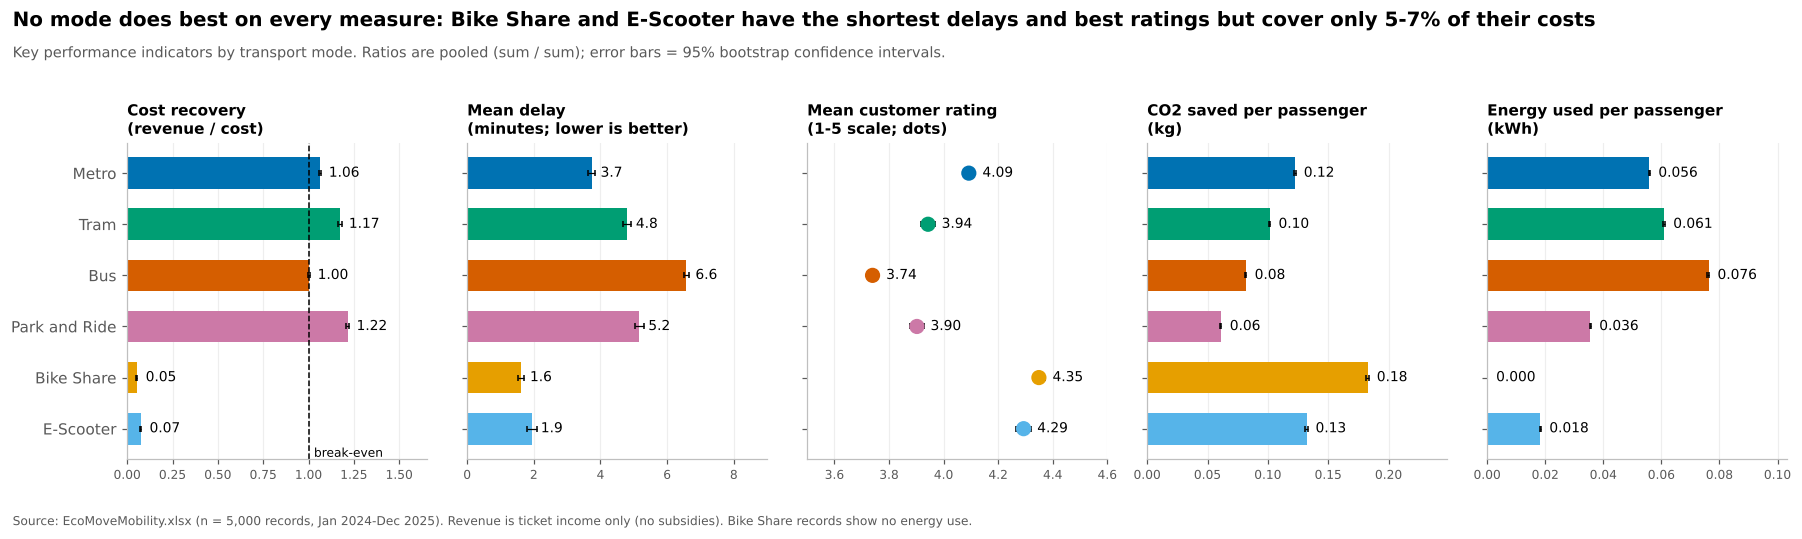

In [74]:
fig = fig5_mode_scorecard(scorecard)
show_figure(fig, 'Fig5_mode_scorecard')

In [75]:
# Report figure - accessibility
def fig6_accessibility_heatmap(rates: pd.DataFrame, route_rates: pd.DataFrame) -> plt.Figure:
    """Complaints per 10k passengers: route type x mode, with an all-modes column."""
    matrix = (rates.pivot(index="Route_Type", columns="Transport_Mode", values="Estimate")
              .reindex(index=ROUTE_ORDER, columns=MODE_ORDER))
    totals = route_rates.set_index("Route_Type").reindex(ROUTE_ORDER)["Estimate"]
    vmax = np.nanmax(matrix.values)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11.5, 5.2),
                                  gridspec_kw={"width_ratios": [6, 1.1], "wspace": 0.05})
    for a, data in ((ax, matrix.values), (ax2, totals.values[:, None])):
        a.imshow(data, cmap="Oranges", vmin=0, vmax=vmax, aspect="auto")
        for i in range(data.shape[0]):
            for j in range(data.shape[1]):
                v = data[i, j]
                a.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=9.5,
                       fontweight="bold" if v > 30 else "normal",
                       color="white" if v > 0.55 * vmax else "black")
        a.grid(False)
        for s in a.spines.values():
            s.set_visible(False)
    ax.set_xticks(range(len(MODE_ORDER)), MODE_ORDER)
    ax.set_yticks(range(len(ROUTE_ORDER)), ROUTE_ORDER)
    ax2.set_xticks([0], ["All modes"])
    ax2.set_yticks([])
    _titles(fig, "Bike Share and E-Scooter on Suburban Feeder routes have about four times "
                 "the complaint rate of the same modes elsewhere",
            "Accessibility complaints per 10,000 passengers (pooled: total complaints / total "
            "passengers in each cell). Darker = higher rate.", y=1.02)
    _footer(fig, "Each cell contains 71-244 records. Micromobility rates rest on small passenger "
                 "volumes (114-150 complaints per Suburban Feeder cell).")
    _finish(fig)
    return fig

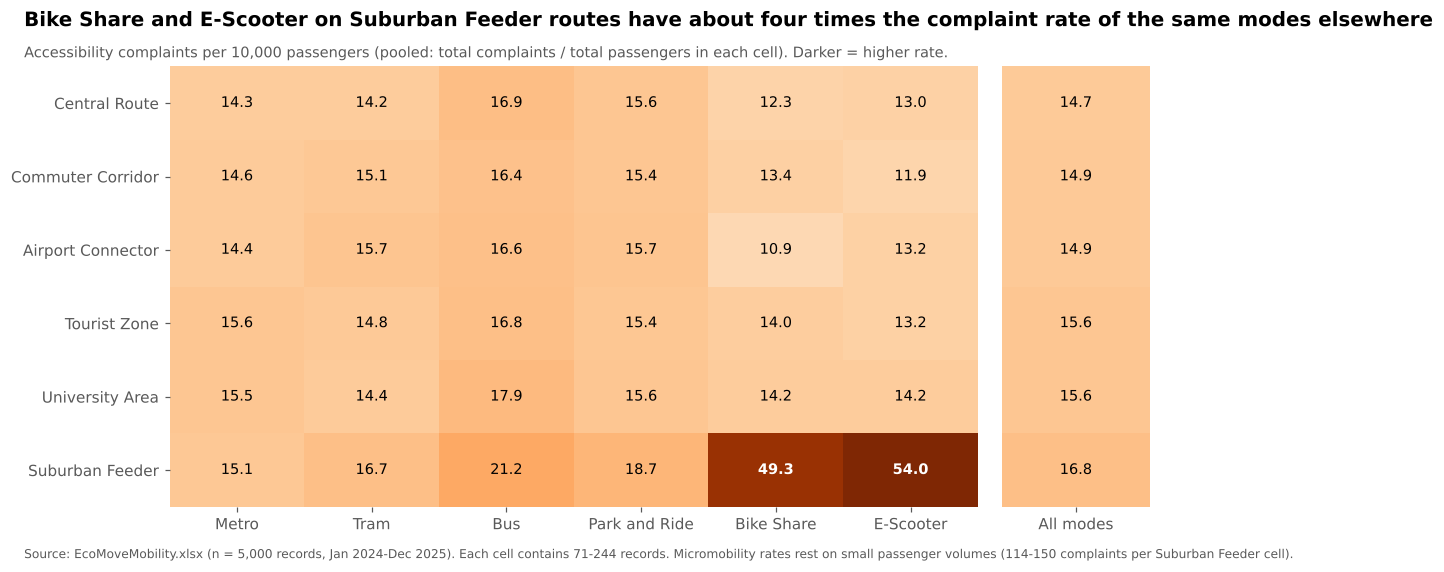

In [76]:
fig = fig6_accessibility_heatmap(route_mode, route_all)
show_figure(fig, 'Fig6_accessibility_heatmap')

In [77]:
# Report figure - environmental vs financial (optional)
def fig7_environment_vs_finance(scorecard: pd.DataFrame, passengers: pd.Series) -> plt.Figure:
    """Bubble chart: cost recovery (x) vs CO2 saved per passenger (y); size = passengers."""
    sc = scorecard.pivot(index="Transport_Mode", columns="KPI", values="Estimate").reindex(MODE_ORDER)
    x = sc["Revenue / cost (pooled)"]
    y = sc["CO2 saved per passenger (kg)"]
    size = passengers.reindex(MODE_ORDER)
    fig, ax = plt.subplots(figsize=(11.5, 5.8))
    ax.axvline(1.0, color="black", lw=1, ls="--")
    ax.text(1.005, 0.195, "break-even", fontsize=8, va="top")
    ax.scatter(x, y, s=size / size.max() * 3000 + 60,
               color=[MODE_COLOURS[m] for m in MODE_ORDER],
               alpha=0.85, edgecolor="white", lw=2, zorder=3)
    offsets = {"Metro": (0.06, 0.012), "Tram": (0.05, 0.010), "Bus": (-0.05, -0.016),
               "Park and Ride": (0.0, -0.016), "Bike Share": (0.06, 0.0), "E-Scooter": (0.06, 0.0)}
    for m in MODE_ORDER:
        dx, dy = offsets[m]
        ax.text(x[m] + dx, y[m] + dy, f"{m}\n{size[m] / 1e6:.1f}m pax", fontsize=8.5,
                ha="left" if dx > 0 else ("center" if dx == 0 else "right"), va="center")
    ax.set_xlim(-0.05, 1.45)
    ax.set_ylim(0.03, 0.21)
    ax.set_xlabel("Cost recovery (pooled ticket revenue / operating cost)")
    ax.set_ylabel("CO2 saved per passenger (kg)")
    ax.grid(axis="x", color="#E6E6E6")
    _titles(fig, "The modes that save the most CO2 per passenger cover the smallest share "
                 "of their costs",
            "Each bubble is a transport mode; bubble area is proportional to total passengers in the sample.")
    _footer(fig, "Mass-transit modes cover their costs while saving 0.06-0.12 kg CO2 per passenger; "
                 "micromobility saves 0.13-0.18 kg but needs about EUR 20 of support per passenger.")
    _finish(fig)
    return fig

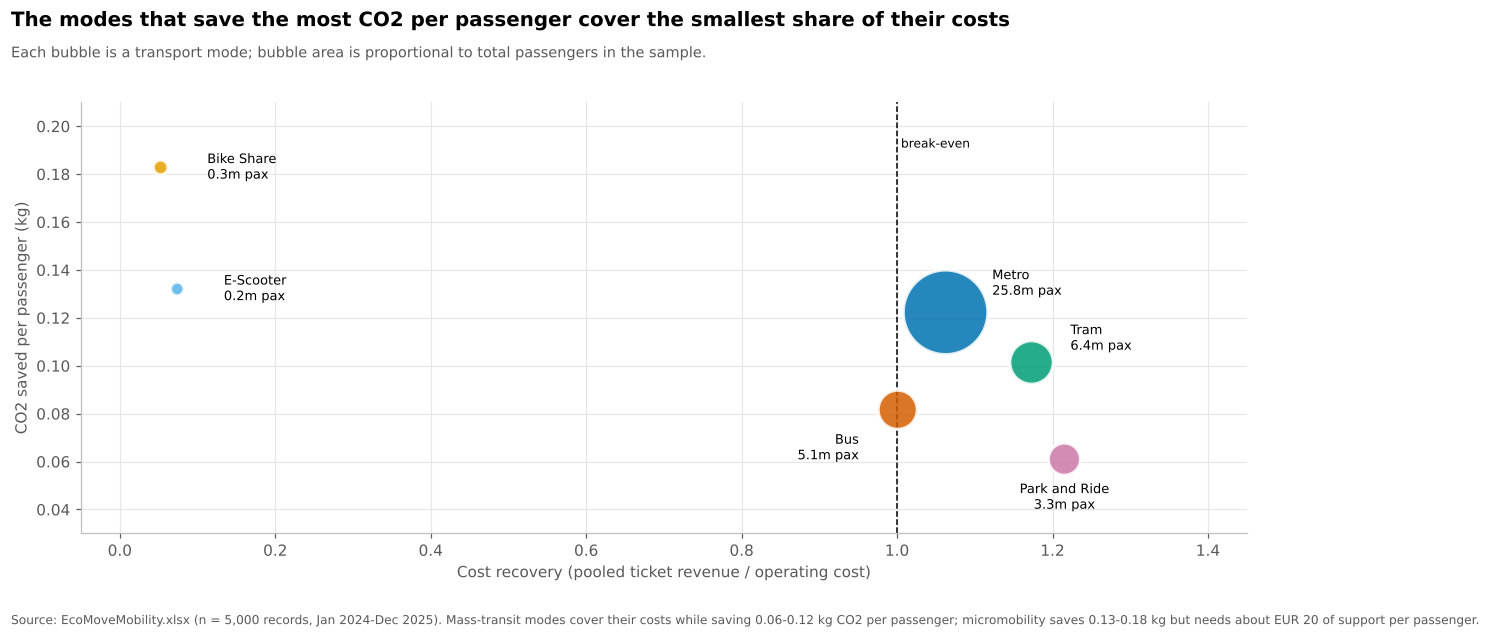

In [78]:
pax = data.groupby('Transport_Mode', observed=True)['Passengers'].sum()
fig = fig7_environment_vs_finance(scorecard, pax)
show_figure(fig, 'Fig7_environment_vs_finance')

In [79]:
# Report figure - event days (optional)
def fig8a_event_day_passengers(uplift: pd.DataFrame) -> plt.Figure:
    """Passenger uplift on event days, one bar per mode (demand)."""
    modes = MODE_ORDER
    u = uplift.reindex(modes)
    y = np.arange(len(modes))
    fig, ax = plt.subplots(figsize=(9, 4.4))
    ax.barh(y, u["Passenger uplift (%)"], color=[MODE_COLOURS[m] for m in modes], height=0.6)
    for yi, v in enumerate(u["Passenger uplift (%)"]):
        ax.text(v + 0.8, yi, f"+{v:.0f}%", va="center", fontsize=9)
    ax.set_xlim(0, 45)
    ax.set_xlabel("Change in mean passengers per record on event days (%)")
    ax.set_yticks(y, modes)
    ax.invert_yaxis()
    ax.grid(axis="x", color="#EEEEEE")
    ax.grid(axis="y", visible=False)
    _titles(fig, "On event days every mode carries 25-37% more passengers per record",
            "Mean passengers per record, event vs non-event days (510 event-day records). Rise significant "
            "in every mode (Mann-Whitney U, Holm-adjusted p < 0.01).")
    _footer(fig)
    _finish(fig)
    return fig


def fig8b_event_day_delay(uplift: pd.DataFrame) -> plt.Figure:
    """Mean delay on non-event and event days, one dumbbell per mode (reliability)."""
    modes = MODE_ORDER
    u = uplift.reindex(modes)
    y = np.arange(len(modes))
    fig, ax = plt.subplots(figsize=(9, 4.4))
    ax.hlines(y, u["Delay (no event)"], u["Delay (event)"], color=LIGHT_NEUTRAL, lw=3)
    ax.scatter(u["Delay (no event)"], y, s=60, color="white", edgecolor=NEUTRAL, lw=1.5,
               zorder=3, label="Non-event day")
    ax.scatter(u["Delay (event)"], y, s=60, color=HIGHLIGHT, zorder=3, label="Event day")
    for yi, (d0, d1) in enumerate(zip(u["Delay (no event)"], u["Delay (event)"])):
        ax.text(d1 + 0.15, yi, f"+{d1 - d0:.1f} min", va="center", fontsize=9)
    ax.set_xlim(0, 9)
    ax.set_xlabel("Average delay per record (minutes)")
    ax.set_yticks(y, modes)
    ax.invert_yaxis()
    ax.legend(loc="lower right", fontsize=8.5)
    ax.grid(axis="x", color="#EEEEEE")
    ax.grid(axis="y", visible=False)
    _titles(fig, "On event days delays are 1.0-1.5 minutes longer in every mode",
            "Mean delay per record, non-event vs event days (510 event-day records). Rise significant "
            "in every mode (Mann-Whitney U, Holm-adjusted p < 0.01).")
    _footer(fig)
    _finish(fig)
    return fig

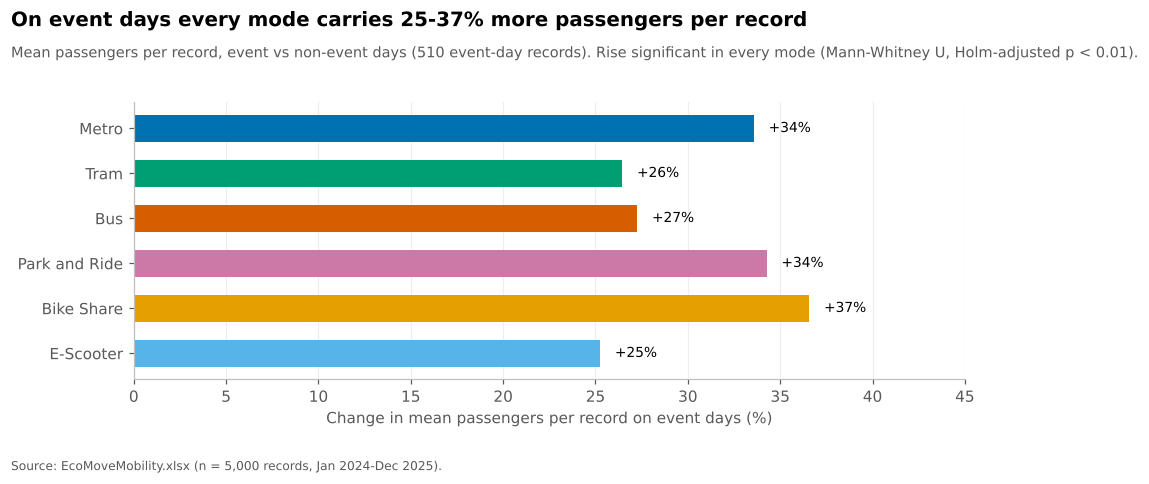

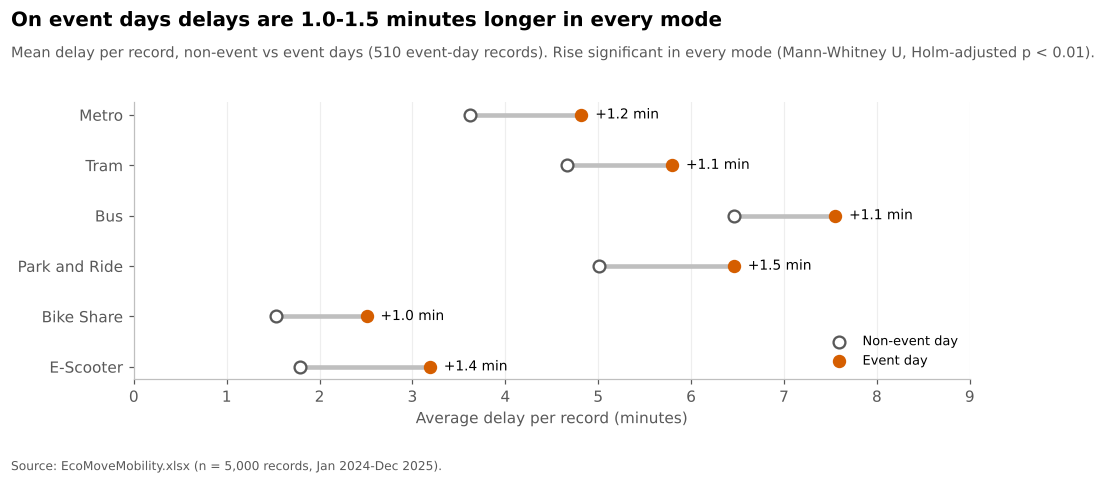

In [80]:
fig = fig8a_event_day_passengers(uplift)
show_figure(fig, 'Fig8a_event_day_passengers')
fig = fig8b_event_day_delay(uplift)
show_figure(fig, 'Fig8b_event_day_delay')

## 2.15 Key numbers for the report (computed, not typed)

In [81]:
net = data.assign(Net=data['Operating_Cost_EUR'] - data['Ticket_Revenue_EUR'])
micro = net[net['Mode_Group'] == 'Micromobility']
key = pd.Series({
    'Total passengers (m)': data['Passengers'].sum() / 1e6,
    'Network revenue/cost': data['Ticket_Revenue_EUR'].sum() / data['Operating_Cost_EUR'].sum(),
    'Network surplus (EUR m)': data['Operating_Surplus_EUR'].sum() / 1e6,
    'Micromobility deficit (EUR m)': micro['Net'].sum() / 1e6,
    'Micromobility share of passengers (%)': 100 * micro['Passengers'].sum() / data['Passengers'].sum(),
    'Micromobility share of CO2 saved (%)': 100 * micro['CO2_Saved_KG'].sum() / data['CO2_Saved_KG'].sum(),
    'Micromobility net cost per tonne CO2 saved (EUR)': micro['Net'].sum() / (micro['CO2_Saved_KG'].sum() / 1000),
    'Loss-making records (%)': 100 * data['Is_Loss_Making'].mean(),
    'Rating change per extra minute delay': rating.params['Average_Delay_Minutes'],
    'Snow extra delay vs clear (min)': delay.params[[i for i in delay.params.index if 'Snow' in i][0]],
    'Event-day extra delay (min, adjusted)': delay.params[[i for i in delay.params.index if 'Event' in i][0]],
})
display(key.round(3))

Total passengers (m)                                    40.910
Network revenue/cost                                     0.996
Network surplus (EUR m)                                 -0.469
Micromobility deficit (EUR m)                            8.878
Micromobility share of passengers (%)                    1.058
Micromobility share of CO2 saved (%)                     1.579
Micromobility net cost per tonne CO2 saved (EUR)   125,418.366
Loss-making records (%)                                 45.440
Rating change per extra minute delay                    -0.121
Snow extra delay vs clear (min)                          4.436
Event-day extra delay (min, adjusted)                    1.175
dtype: float64